# Assignment 3 - Application of Clustering

In this assignment, we are tasked with predicting whether a given transaction is fraudulent or not. We are given a dataset on pre-processed credit card transactions and we have to train a Logistic Regression model on it for the same. The catch here is, the dataset, similar to the real world, is highly imbalanced i.e. the number of fraud transactions are very few in the same. We must figure out on how to build a model which can catch this problem despite this issue.

## Imports

Only for Colab

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# !cp /content/drive/MyDrive/kaggle.json /content/kaggle.json
# !mkdir -p /root/.config/kaggle
# !cp kaggle.json /root/.config/kaggle
# !chmod 600 /root/.config/kaggle/kaggle.json

In [3]:
import numpy as np
import pandas as pd
import json

import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import kaggle
from kagglehub import KaggleDatasetAdapter

import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
from sklearn.cluster import *
from sklearn.kernel_approximation import Nystroem
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import KernelPCA
from sklearn.model_selection import train_test_split, GridSearchCV

import imblearn
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import *
from imblearn.under_sampling import *
from imblearn.metrics import *

## PART A : Data Exploration

Going through the Kaggle Data Information page, we note the following:
1. The dataset is already processed into numeric values to hide sensitive information (hence no need for encoding).
2. PCA has already been performed and we are given some of its principal components.
3. Two additional features are provided -
a. Time: Time elapsed in seconds since the first transaction
b. Amount: Monetary amount
4. Class contains the binary target labels

Also, as the dataset size is too big, you would have to download from the Kaggle website with your API key

In [4]:
kaggle.api.dataset_download_files('mlg-ulb/creditcardfraud', path='./data', unzip=True)

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud


In [5]:
data = pd.read_csv('data/creditcard.csv')  # load the dataset

In [6]:
data    # display some of its rows

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [7]:
data.describe()  # some statistics on it

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


To see the class imbalance:

In [8]:
neg_class = data[data['Class'] == 0]
pos_class = data[data['Class'] == 1]
neg_class_count, pos_class_count = data['Class'].value_counts()
print(f"Percentage of Positive Class data points: {len(pos_class)/ len(data) * 100}")
print(f"Percentage of Negative Class data points: {len(neg_class)/ len(data) * 100}")
print(f"Ratio of number of Negative Class to that of Positive Class : {(neg_class_count) / pos_class_count}")

Percentage of Positive Class data points: 0.1727485630620034
Percentage of Negative Class data points: 99.82725143693798
Ratio of number of Negative Class to that of Positive Class : 577.8760162601626


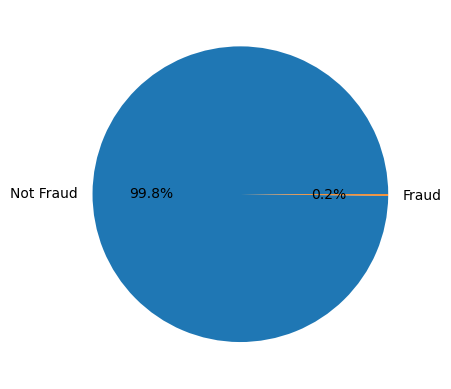

In [9]:
plt.pie(x = [neg_class_count, pos_class_count], labels=['Not Fraud', 'Fraud'], autopct='%1.1f%%')
plt.savefig('images/pie_chart_class_dis.png')
plt.show()

#### Why is this bad?
1. Most of classifiers (like Logistic Regression) is built on the assumption that the dataset is balanced.
2. Standard classification algorithms often perform poorly on such datasets, as they tend to classify most instances as the majority class to achieve high overall accuracy, ignoring the minority class.
3. The usual metrics used for gauging a model's performance, such as Accuracy, Precision, AUC-ROC and F1, are highly senstitive to the class imbalance and may indicate misleading results.

#### What can be done?
We have three options in hand. We can choose either one or more:
1. Process the Dataset
2. Use better models (which is out of scope for our problem statement)
3. Use better metrics

In [10]:
x, y = data.drop(columns=['Class']), data['Class']

## Pipeline

We define some functions that would be called for each of the resampling methods

In [17]:
def report_generator(y_pred, y_test, name):
    """
        Generate a comprehensive report based on various metrics
        Implemented from sklearn
    """

    x = ["Fraud", "Not Fraud"]
    actual_fraud, predict_fraud = y_test[np.where(y_test == 1)[0]], y_pred[np.where(y_test == 1)[0]]
    actual_not_fraud, predict_not_fraud = y_test[np.where(y_test == 0)[0]], y_pred[np.where(y_test == 0)[0]]

    report = {
        "Fraud": {
            "precision": precision_score(actual_fraud, predict_fraud),
            "recall": recall_score(actual_fraud, predict_fraud),
            "f1": f1_score(actual_fraud, predict_fraud),
            "bal_acc": balanced_accuracy_score(actual_fraud, predict_fraud),
            "accuracy": accuracy_score(actual_fraud, predict_fraud),
            "size": len(actual_fraud)
        },
        "Not Fraud": {
            "precision": precision_score(actual_not_fraud, predict_not_fraud),
            "recall": recall_score(actual_not_fraud, predict_not_fraud),
            "f1": f1_score(actual_not_fraud, predict_not_fraud),
            "bal_acc": balanced_accuracy_score(actual_not_fraud, predict_not_fraud),
            "accuracy": accuracy_score(actual_not_fraud, predict_not_fraud),
            "size": len(actual_not_fraud)
        },
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "pr_curve": precision_recall_curve(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "confusion_matrix": confusion_matrix(y_test, y_pred),
        "roc_curve": roc_curve(y_test, y_pred),
        "likelihood_ratios": class_likelihood_ratios(y_test, y_pred),
        "bal_acc": balanced_accuracy_score(y_test, y_pred),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "accuracy": accuracy_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_pred),
        "avg_p": average_precision_score(y_test, y_pred)
    }
    fraud, not_fraud = report['Fraud'], report['Not Fraud']

    fig, axs = plt.subplots(3, 2, figsize= (10, 10), constrained_layout = True)
    color_palette = [
        '#0072B2',  # Cerulean Blue
        '#D55E00',  # Vermillion
    ]
    k, l = 0, 0
    for i, j in zip(fraud, not_fraud):
        if i != 'size':
            y = [fraud[i], not_fraud[j]]
            axs[k, l].bar(x, height = y, color = color_palette)
            axs[k, l].set_ylim(0, 1.1)
            axs[k, l].set_ylabel(f"{i.capitalize()} Value")
        else:
            y = [np.log(fraud[i]), np.log(not_fraud[j])]
            axs[k, l].bar(x, height = y, color = color_palette)
            axs[k, l].set_ylabel(f"Log of {i.capitalize()} Value")
        
        for q in range(len(x)):
            axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

        axs[k, l].set_title(f"{i.capitalize()} Comparison")
        l += 1
        if l == 2:
            k += 1
            l = 0

    fig.suptitle(f"Comparison of Metrics between Fraud and Not Fraud Classes in {name}")
    fig.align_xlabels(axs)
    plt.subplots_adjust(wspace=0.3, hspace=0.4)
    plt.savefig(f"images/{name}_report_skelearn.png")
    plt.show()

    cm = ConfusionMatrixDisplay(confusion_matrix=report['confusion_matrix'], display_labels=x[::-1])
    cm.plot()
    plt.savefig(f"images/Confusion_mat_{name}.png")
    plt.show()

    pr = PrecisionRecallDisplay.from_predictions(y_test, y_pred)
    pr.plot()
    plt.savefig(f"images/PR_Curve_{name}.png")
    plt.show()

    roc = RocCurveDisplay.from_predictions(y_test, y_pred)
    roc.plot()
    plt.savefig(f"images/ROC_Curve_{name}.png")
    plt.show()

    return report

In [18]:
def imbalanced_report_generator(y_pred, y_test, name):
    """
        Generate a comprehensive report based on various metrics
        Implemented from imblearn
    """

    report = classification_report_imbalanced(y_test, y_pred,
    labels=[0, 1], target_names=['Not Fraud', 'Fraud'], output_dict=True)
    d = {
        "pre": "Precison", "rec": "Recall",
        "spe": "Specificity", "f1": "F1 Score",
        "geo": "FM Index", "iba": "IBA",
        "sup": "Support", "avg_pre": "Average Precision",
        "avg_rec": "Average Recall", "avg_spe": "Average Specificity",
        "avg_f1": "Average F1 Score", "avg_geo": "Average FM Index",
        "avg_iba": "Average IBA", "total_support": "Total Support"
    }
    better_report = {
        "Fraud": dict(), "Not Fraud": dict(), 
        "Average Precision": 0,"Average Recall": 0,
        "Average Specificity": 0,
        "Average F1 Score": 0,
        "Average FM Index": 0,
        "Average Index Balanced Accuracy": 0,
        "Total Support": 0
    }
    for i in report:
        if i == "Fraud":
            k = report[i]
            for j in k:
                better_report["Fraud"][d[j]] = k[j]
        elif i == "Not Fraud":
            k = report[i]
            for j in k:
                better_report["Not Fraud"][d[j]] = k[j]
        else:
            better_report[d[i]] = report[i]
    fraud, not_fraud = better_report['Fraud'], better_report['Not Fraud']

    fig, axs = plt.subplots(4, 2, figsize= (10, 10), constrained_layout = True)
    color_palette = [
        '#0072B2',  # Cerulean Blue
        '#009E73',  # Shamrock Green
    ]
    k, l = 0, 0
    for i, j in zip(fraud, not_fraud):
        x = ["Fraud", "Not Fraud"]
        if i != 'Support':
            y = [fraud[i], not_fraud[j]]
            axs[k, l].bar(x, height = y, color=color_palette)
            axs[k, l].set_ylim(0, 1.1)
            axs[k, l].set_ylabel(f"{i} Value")
        else:
            y = [np.log(fraud[i]), np.log(not_fraud[j])]
            axs[k, l].bar(x, height = y, color=color_palette)
            axs[k, l].set_ylabel(f"Log of {i} Value")
        
        for q in range(len(x)):
            axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

        axs[k, l].set_title(f"{i.capitalize()} Comparison")
        l += 1
        if l == 2:
            k += 1
            l = 0

    axs[k, l].bar(x=["Fraud", "Not Fraud"], height=[np.log(len(pos_class)), np.log(len(neg_class))])
    axs[k, l].set_title("Sample Size Comparison")
    axs[k, l].set_xlabel(f"Class")
    axs[k, l].set_ylabel(f"Log of Size Value")
    for q in range(len(x)):
        axs[k, l].text(q, y[q], np.round(y[q], 2), ha='center')  # Aligning text at center

    fig.suptitle(f"Comparison of Metrics between Fraud and Not Fraud Classes in {name}")
    fig.align_xlabels(axs)
    plt.subplots_adjust(wspace=0.3, hspace=0.4)
    plt.savefig(f"images/{name}_report.png")
    plt.show()

    return better_report

In [19]:
def plot_resampling(X, y, sampler, ax, title=None):
    """
        Plot the data points with labels after resampling
    """

    X_res, y_res = sampler.fit_resample(X, y)
    ax.scatter(X_res[:, 0], X_res[:, 1], c=y_res, alpha=0.8, edgecolor="k")
    if title is None:
        title = f"Resampling with {sampler.__class__.__name__}"
    ax.set_title(title)
    sns.despine(ax=ax, offset=10)

In [20]:
def plot_decision_function(X, y, clf, ax, title=None):
    """
        Plot the data points with labels along with Vornoi regions after resampling and classification
    """

    plot_step = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, plot_step), np.arange(y_min, y_max, plot_step)
    )

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.4)
    ax.scatter(X[:, 0], X[:, 1], alpha=0.8, c=y, edgecolor="k")
    if title is not None:
        ax.set_title(title)

In [21]:
def classify(data, name, balanced=False, sampler = None):
    """
        The main pipeline code
    """

    # First Standardize the data
    x, y = StandardScaler().fit_transform(data.drop(columns=['Class']).to_numpy()), data['Class'].to_numpy()
    X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.25)
    
    pipeline = []
    if sampler is not None:
        pipeline.append(('sampler', sampler))
    if balanced:  # if we want to test with balanced class weights
        pipeline.append(('log_reg', LogisticRegression(solver="lbfgs", class_weight='balanced')))
    else:
        pipeline.append(('log_reg', LogisticRegression(solver="lbfgs")))
    pipeline = Pipeline(pipeline)

    model = pipeline.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r1 = report_generator(y_pred, y_test, name)
    r2 = imbalanced_report_generator(y_pred, y_test, name)
    
    k = ['precision','recall','f1','bal_acc','mcc','accuracy','roc_auc','avg_p']
    new_r1 = {i: r1[i] for i in k}
    new_r1['positive_likelihood_ratio'] = r1['likelihood_ratios'][0]
    new_r1['negative_likelihood_ratio'] = r1['likelihood_ratios'][1]
    new_r1['name'] = name
    df = pd.DataFrame.from_dict(new_r1, orient='index', columns=['Score']).transpose()

    return model, r1, r2, df

In [ ]:
classifiers = dict()
samplers = dict()
sk_reports = dict()
im_reports = dict()
total_df = dict()

In [23]:
def show_decision_functions(data):
    """
        Show a comprehensive plot of all decision plots and resampling result of each resampling method
    """

    clfs = classifiers
    data2 = data.sample(n=100000, axis=0)
    fig, axs = plt.subplots(nrows=len(samplers), ncols=2, figsize=(30, 30))

    # Left plot : Decision plot ; Right plot : Resampling method
    for ax, sampler, clf in zip(axs, samplers, clfs):
        name = "None" if sampler is None else sampler.__class__.__name__
        cur_X, cur_Y = data2.drop(columns=['Class'])[['V1', 'V2']].to_numpy(), data2['Class'].to_numpy()
        plot_decision_function(cur_X, cur_Y, clf, ax[0], title=f"Using {name}")
        if sampler:
            plot_resampling(cur_X, cur_Y, sampler, ax[1], title=f"{name}")

    fig.suptitle(f"Decision function of Logistic Regression")
    fig.tight_layout()
    fig.savefig('images/decision_functions_cum.png')

## PART A : Straight Classification

What if we decide to classify directly without taking in account the class imbalance?

### Unbalanced Logistic Regression

Taking equal class weights in Logistic Regression

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


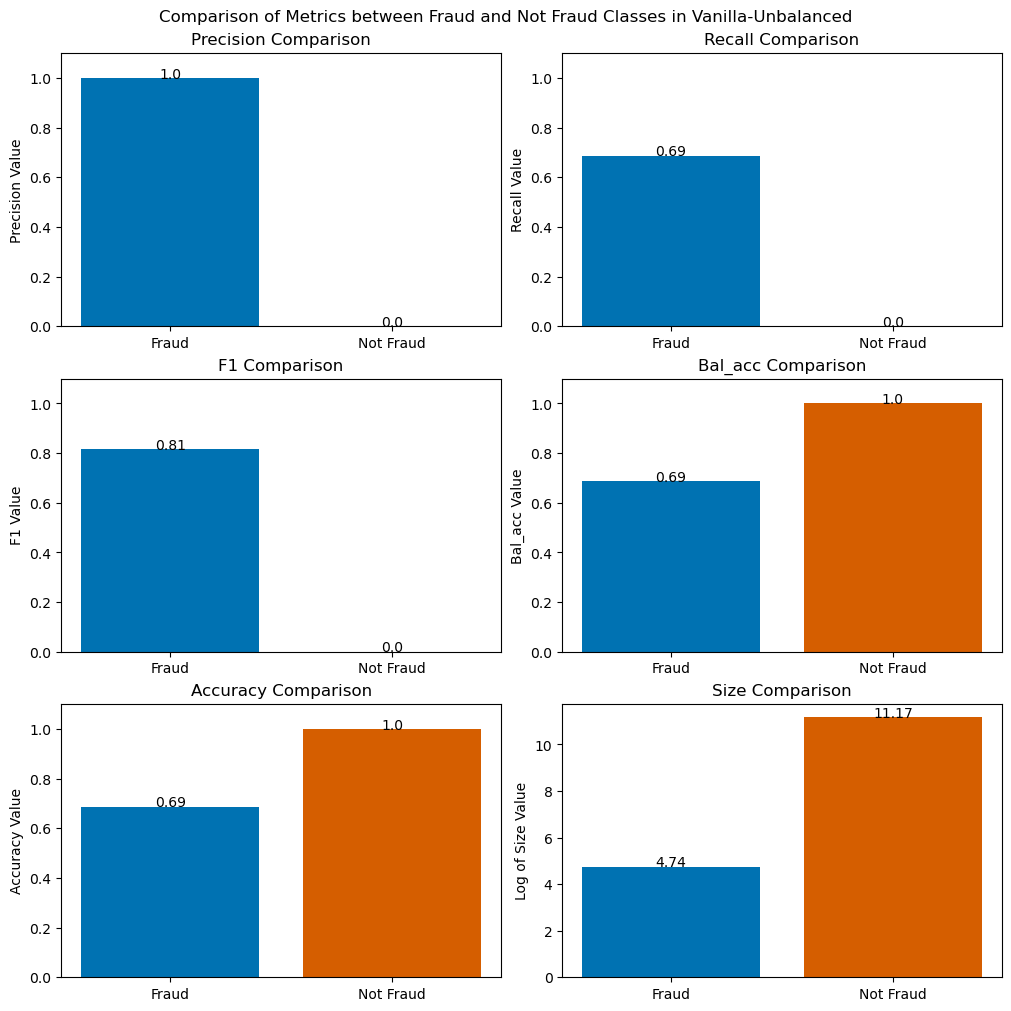

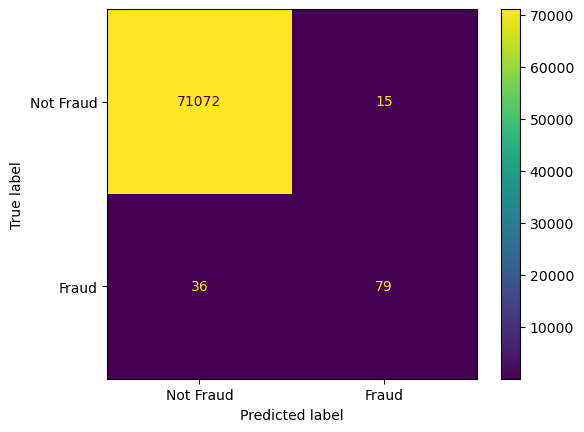

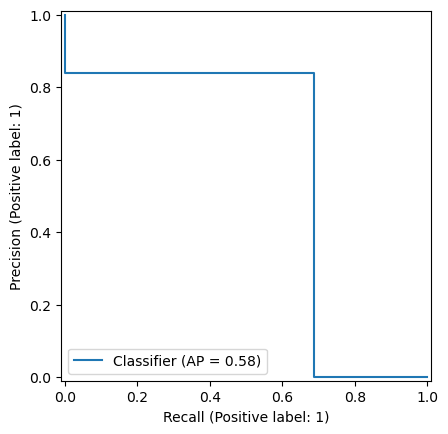

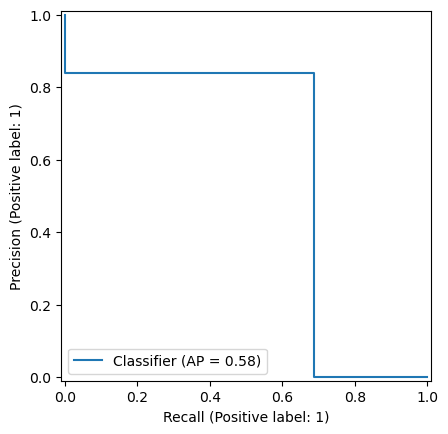

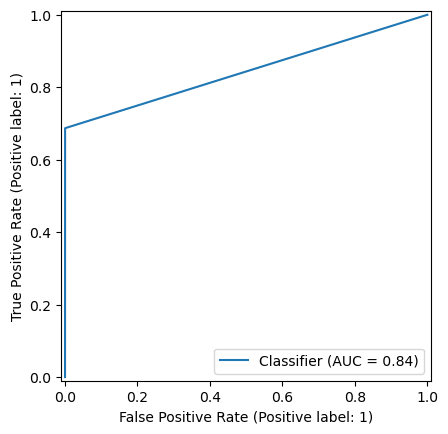

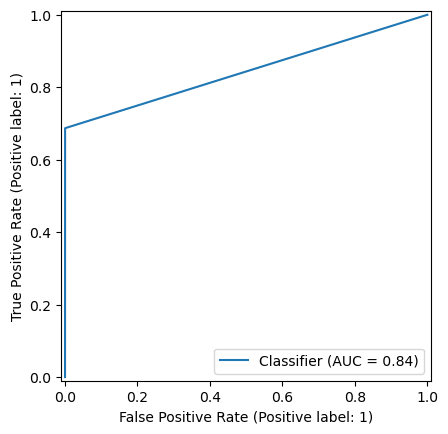

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


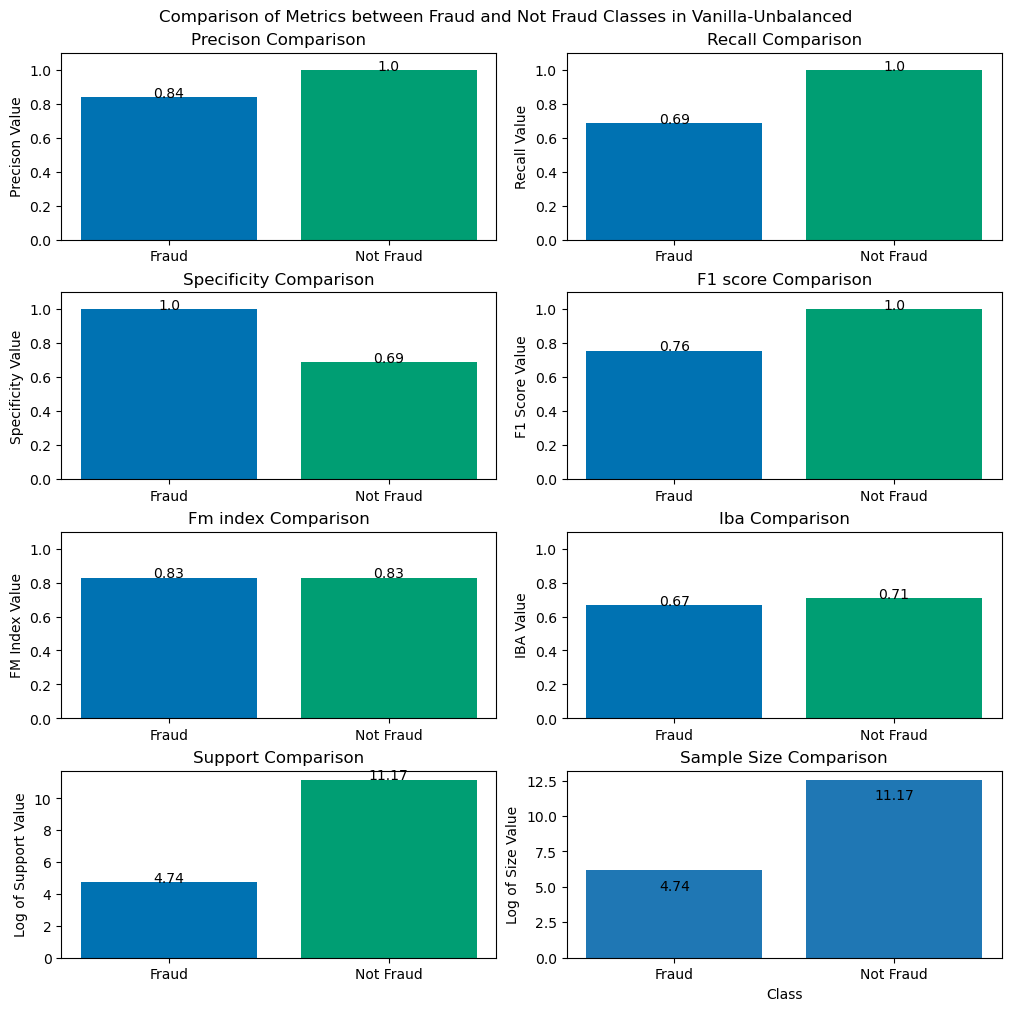

In [24]:
name="Vanilla-Unbalanced"
model, r1, r2, df = classify(data, name=name)
samplers[name] = None
classifiers[name] = model
sk_reports[name] = r1
im_reports[name] = r2
total_df[name] = df

In [25]:
df

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.840426,0.686957,0.755981,0.843373,0.759481,0.999284,0.843373,0.577841,3255.578551,0.31311,Vanilla-Unbalanced


Observations:
1. Precision is high, which means the model is careful on its predictions.
2. Recall is moderate (Precision and Recall share an approximate inverse relation) which means it misses some of the Fraud points
3. Accuracy is very high (99%)

These support our original hypothesis of the data being highly imbalanced.

### Balanced Logistic Regression

Let's see what happens when we supply a balanced class weight to the classifier

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


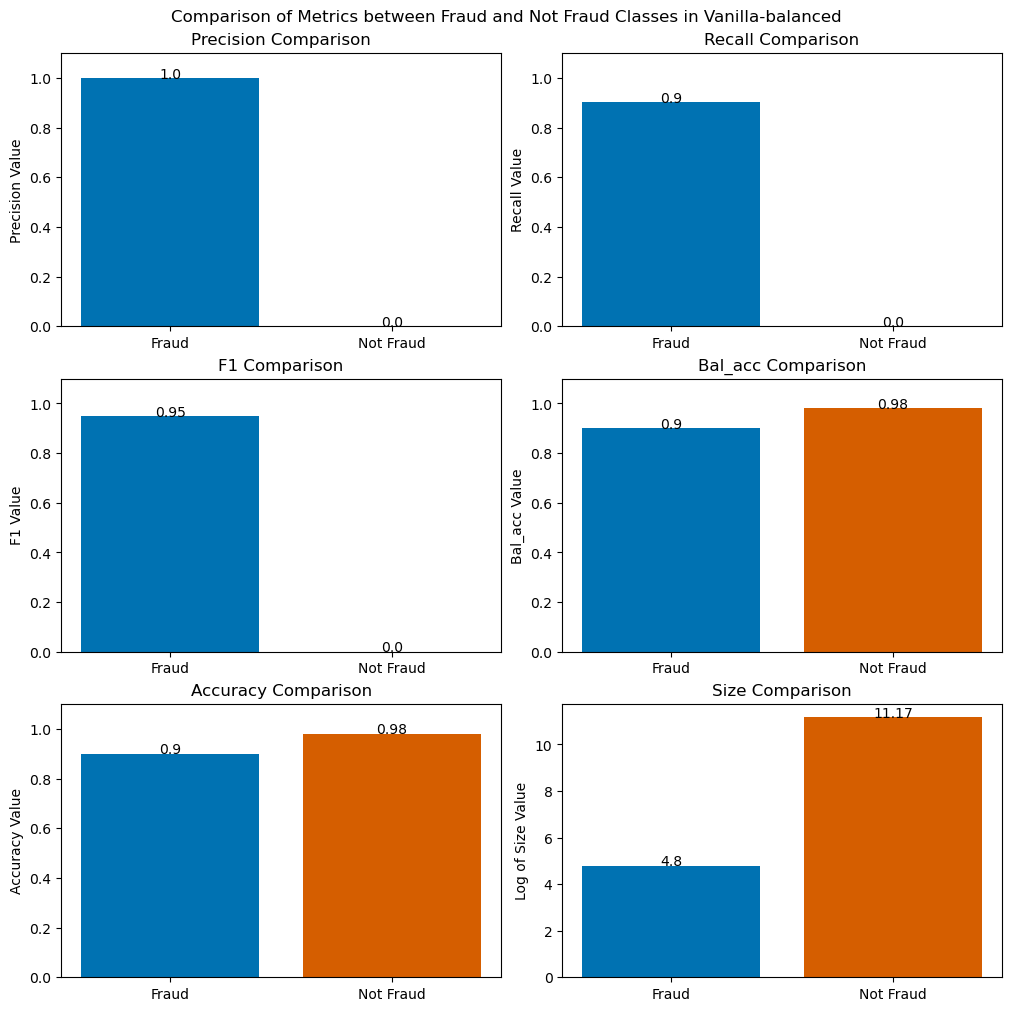

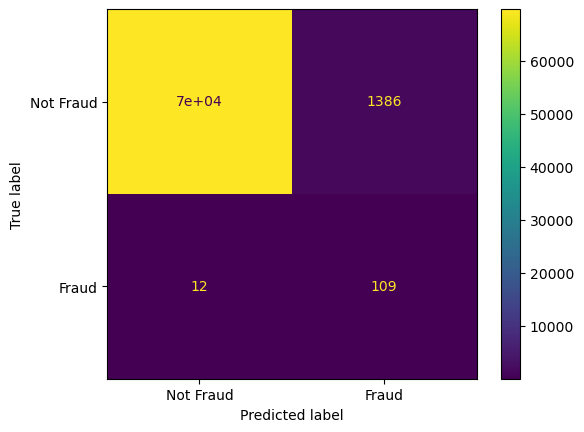

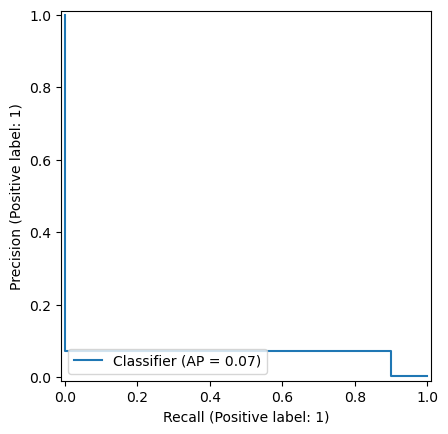

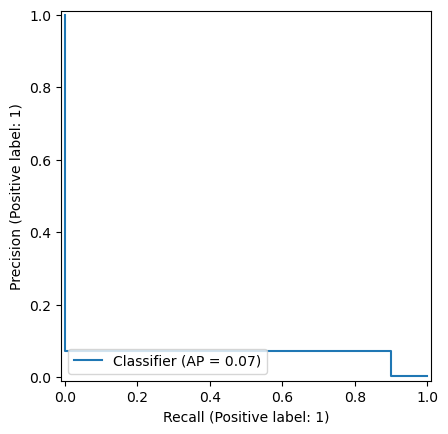

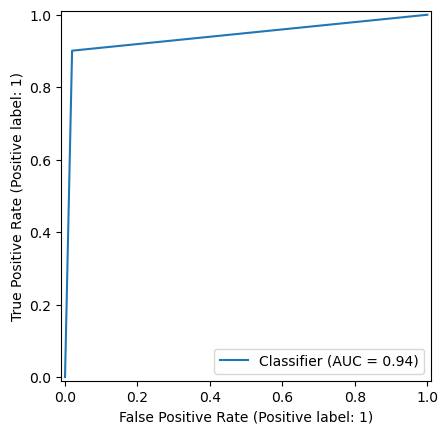

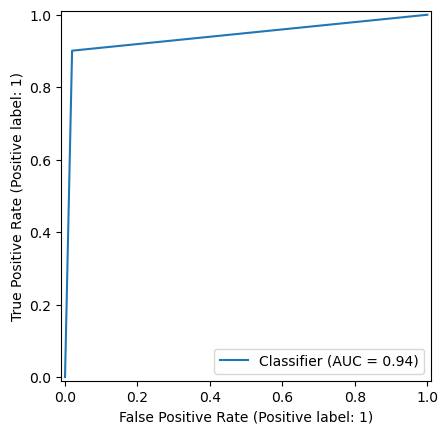

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


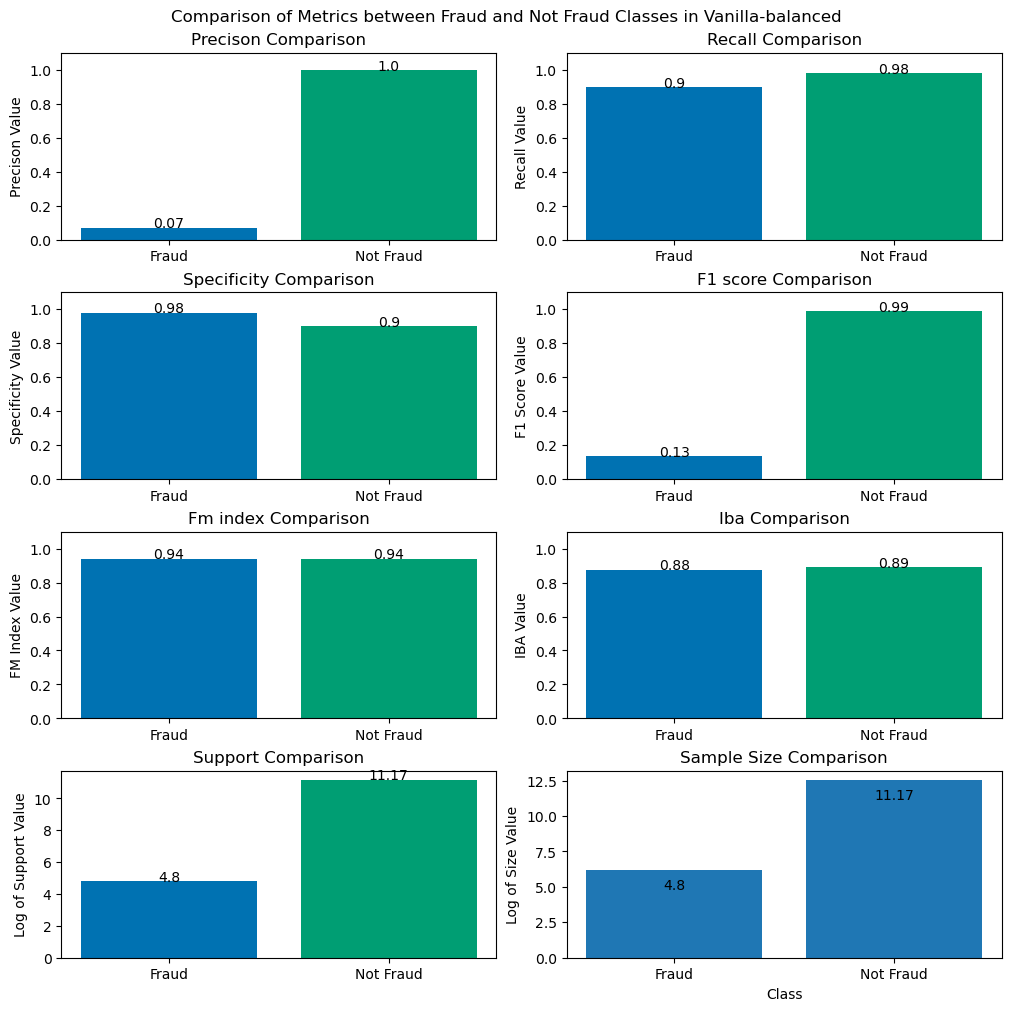

In [26]:
name = "Vanilla-balanced"
model, r1, r2, df = classify(data, name=name, balanced=True)
samplers[name] = None
classifiers[name] = model
sk_reports[name] = r1
im_reports[name] = r2
total_df[name] = df

In [27]:
df

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.07291,0.900826,0.134901,0.940664,0.253191,0.980366,0.940664,0.065848,46.198878,0.101146,Vanilla-balanced


Some Observations:
1. Precision is very poor while Recall is better
2. F1 score is very poor
3. Accuracy has decreased, but still high

## PART B : Apply Sampling Methods

The Dataset needs to be transformed (or more appropriately, resampled) to represent a better class distribution. Resampling means we can either <b>under-sample</b> from the majority class or <b>over-sample</b> from the minority class

### Over-sampling

We can add more examples from the minority class in the dataset to improve its percentage. There are different ways of doing the same:

#### Random Over-sampling

Randomly duplicate the records in the minority class.<br>
1. **Pro**:    Simple & Fast
2. **Con**:    Highlight specific datapoints in the class rather than generalize

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


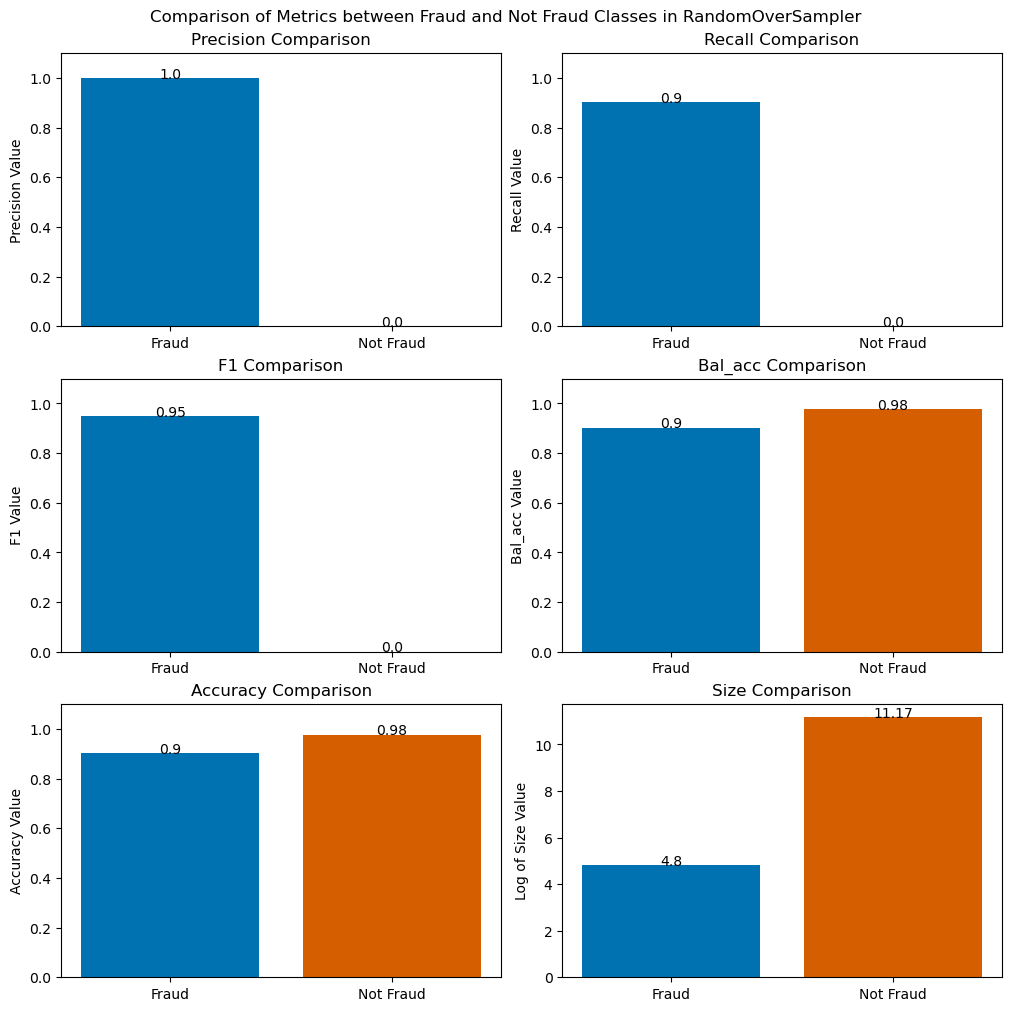

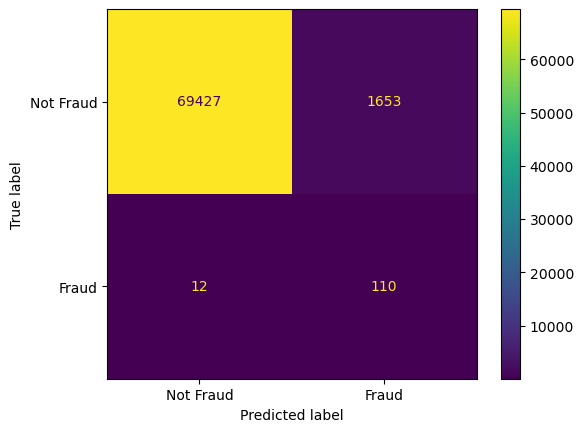

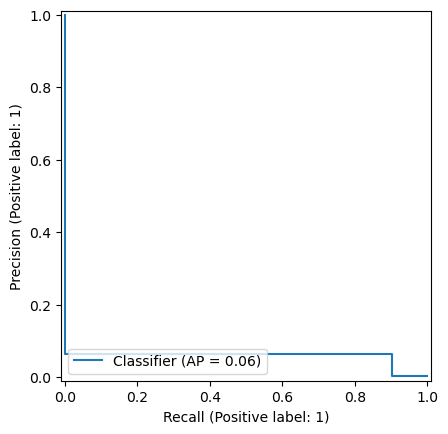

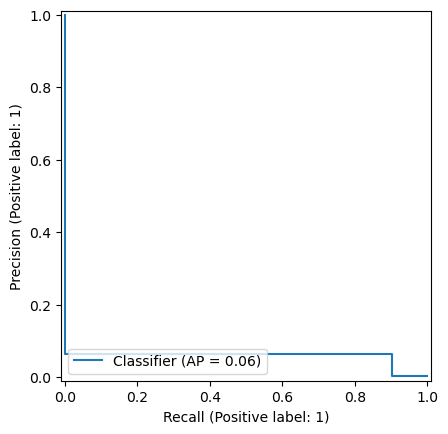

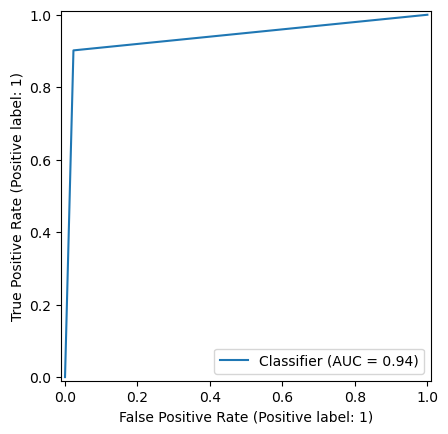

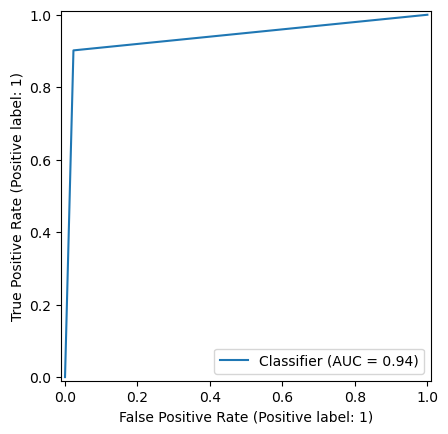

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


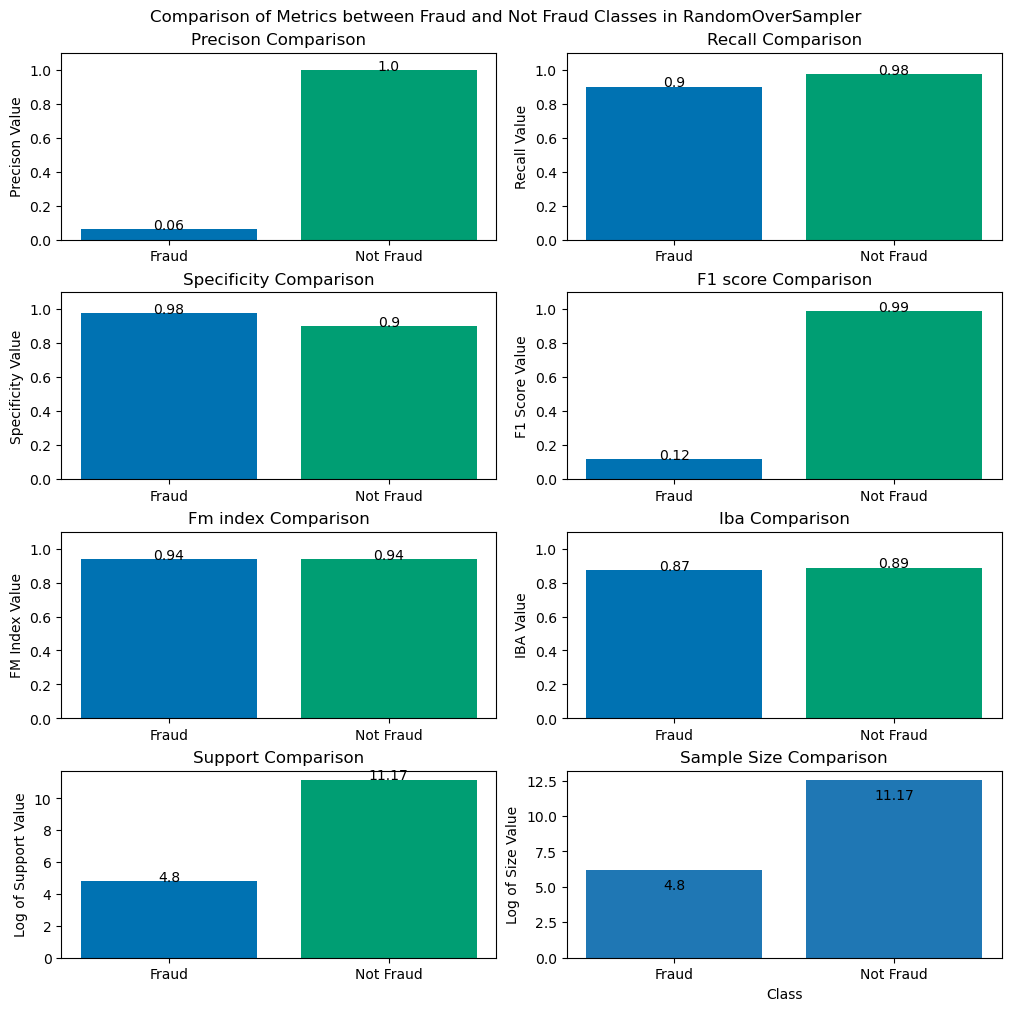

In [28]:
ros = RandomOverSampler(random_state=42)
ros.set_params(shrinkage=None)
name = "RandomOverSampler"
model, r1, r2, df = classify(data, name=name, sampler=ros)
samplers[name] = ros
classifiers[name] = model
sk_reports[name] = r1
im_reports[name] = r2
total_df[name] = df

In [29]:
df

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.062394,0.901639,0.116711,0.939192,0.233781,0.976616,0.939192,0.056425,38.771037,0.100703,RandomOverSampler


Some Observations:
1. The model showcases High Recall and Low Precision
2. F1 Score fails
3. Very low Average Precision

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


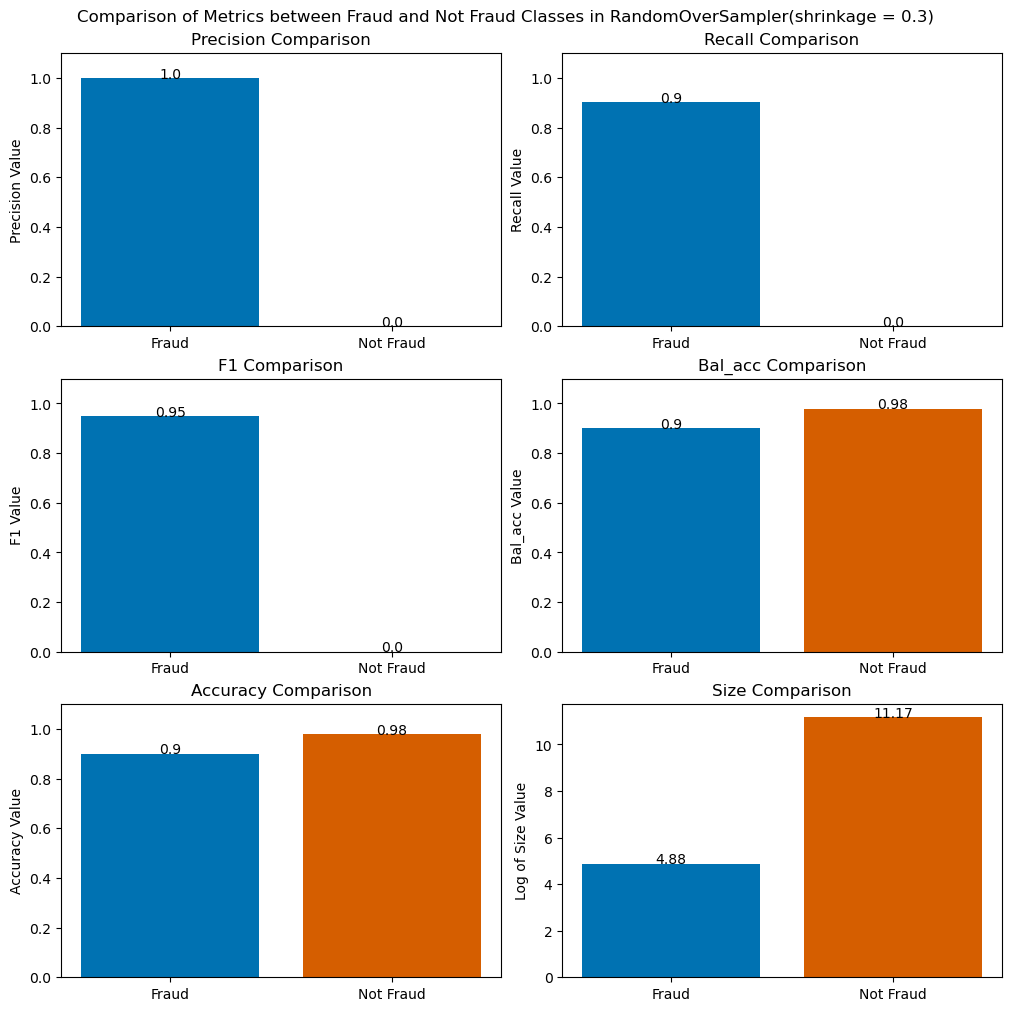

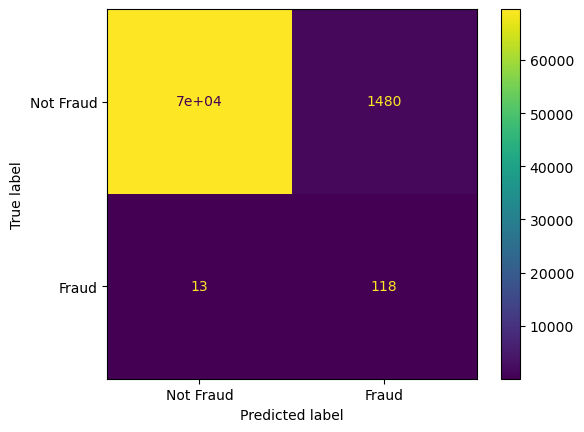

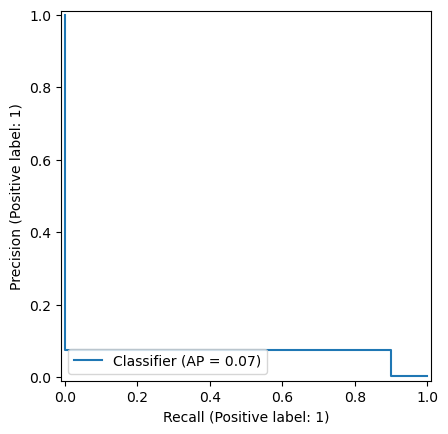

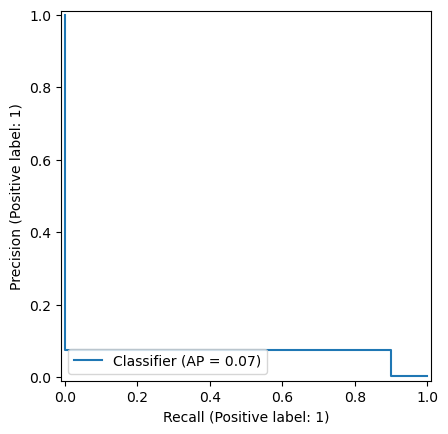

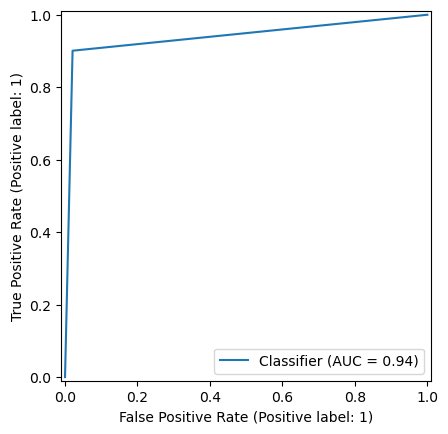

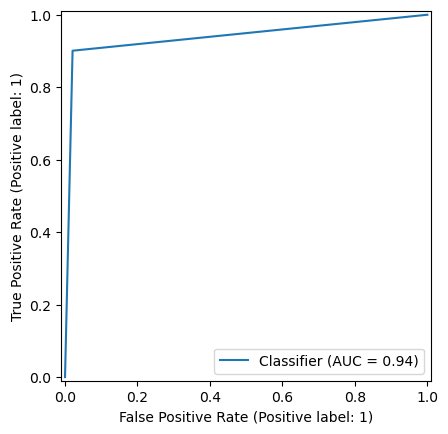

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


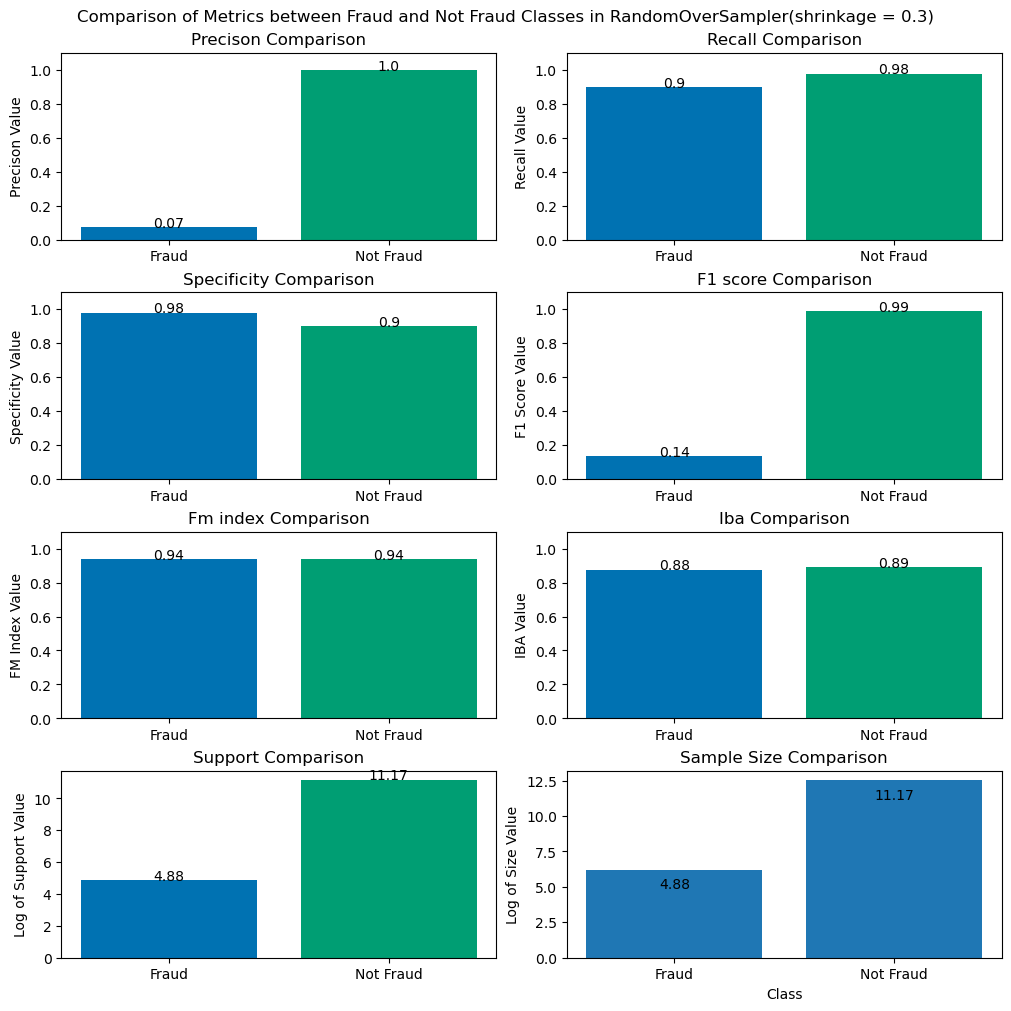

In [30]:
ros = RandomOverSampler(random_state=42)
ros.set_params(shrinkage=0.3)
name = "RandomOverSampler(shrinkage = 0.3)"
model, r1, r2, df = classify(data, name=name, sampler=ros)
samplers[name] = (ros)
classifiers[name] = (model)
sk_reports[name] = (r1)
im_reports[name] = (r2)
total_df[name] = df

#### Synthetic Minority Oversampling Technique (SMOTE)

In this method, we add synthetic data points in the minority class keeping the features of the data roughly maintained. We do so by using the k-nearest neighbors method.

SMOTE algorithm works in 4 simple steps:
1. Choose a minority class as the input vector.
2. Find its k nearest neighbors (k_neighbors is specified as an argument in the SMOTE() function).
3. Choose one of these neighbors and place a synthetic point anywhere on the line joining the point under consideration and its chosen neighbor.
4. Repeat the steps until the data is balanced.

The minority class is over-sampled by taking each minority class sample and introducing synthetic examples along the line segments joining any/all of the k minority class nearest neighbors. Depending upon the amount of over-sampling required, neighbors from the k nearest neighbors are randomly chosen. Default implementation currently uses five nearest neighbors. For instance, if the amount of over-sampling needed is 200%, only two neighbors from the five nearest neighbors are chosen and one sample is generated in the direction of each.

Synthetic samples are generated in the following way: Take the difference between the feature vector (sample) under consideration and its nearest neighbor. Multiply this difference by a random number between 0 and 1, and add it to the feature vector under consideration. This causes the selection of a random point along the line segment between two specific features. This approach effectively forces the decision region of the minority class to become more general.

1. **Pro**: Generates new data, hence reduces overfitting
2. **Con**: Can create noise by indiscriminatively generating points

In [31]:
# Calculate the amount of over-sampling required:
print(f"Amount of Oversampling required for the Positive Class:{neg_class_count / pos_class_count}")

Amount of Oversampling required for the Positive Class:577.8760162601626


We need more than five nearest neighbors to actually perform the job.

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


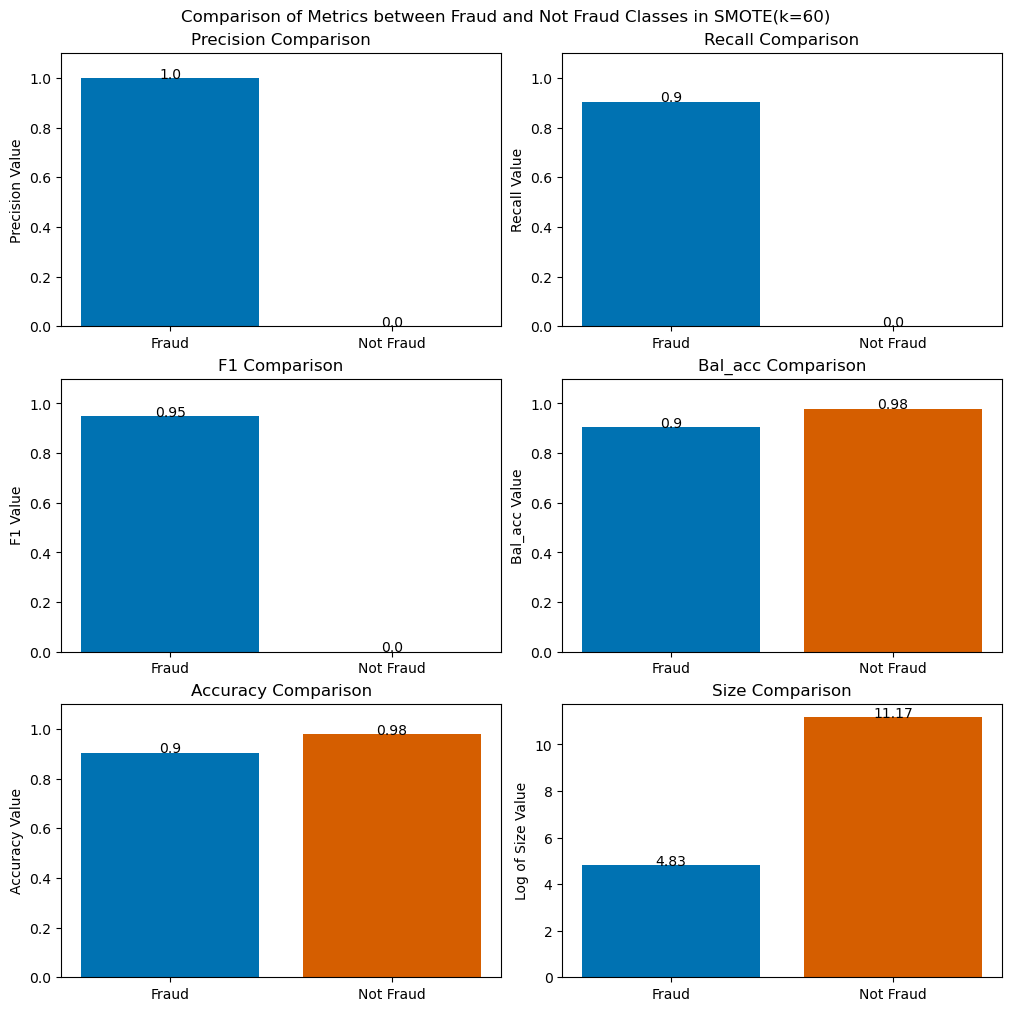

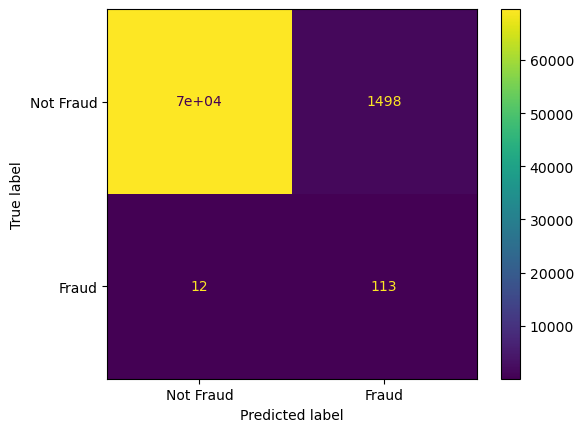

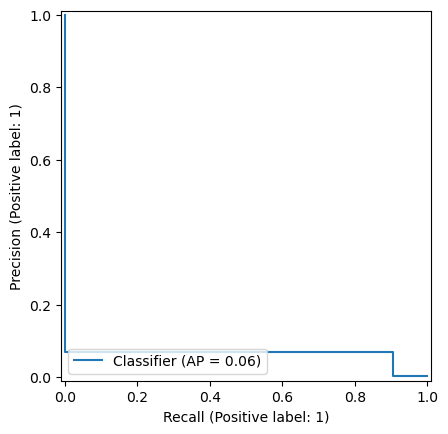

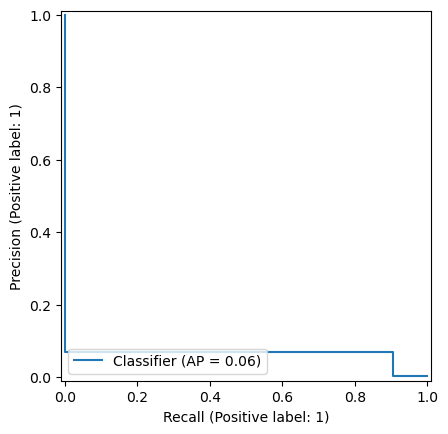

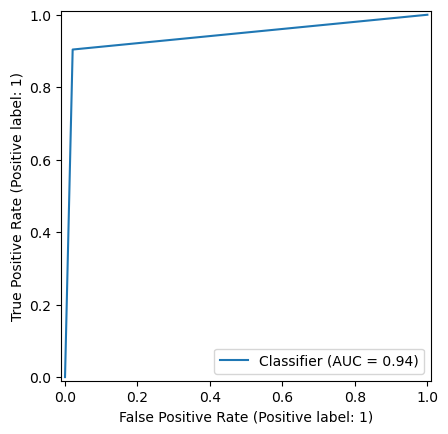

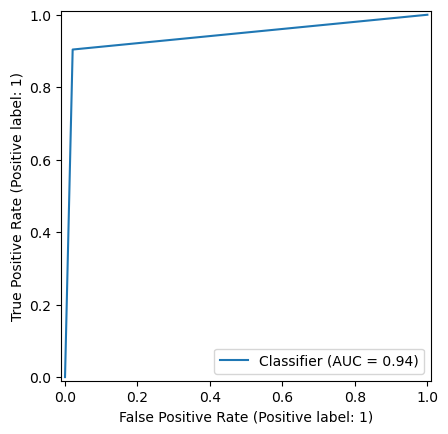

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


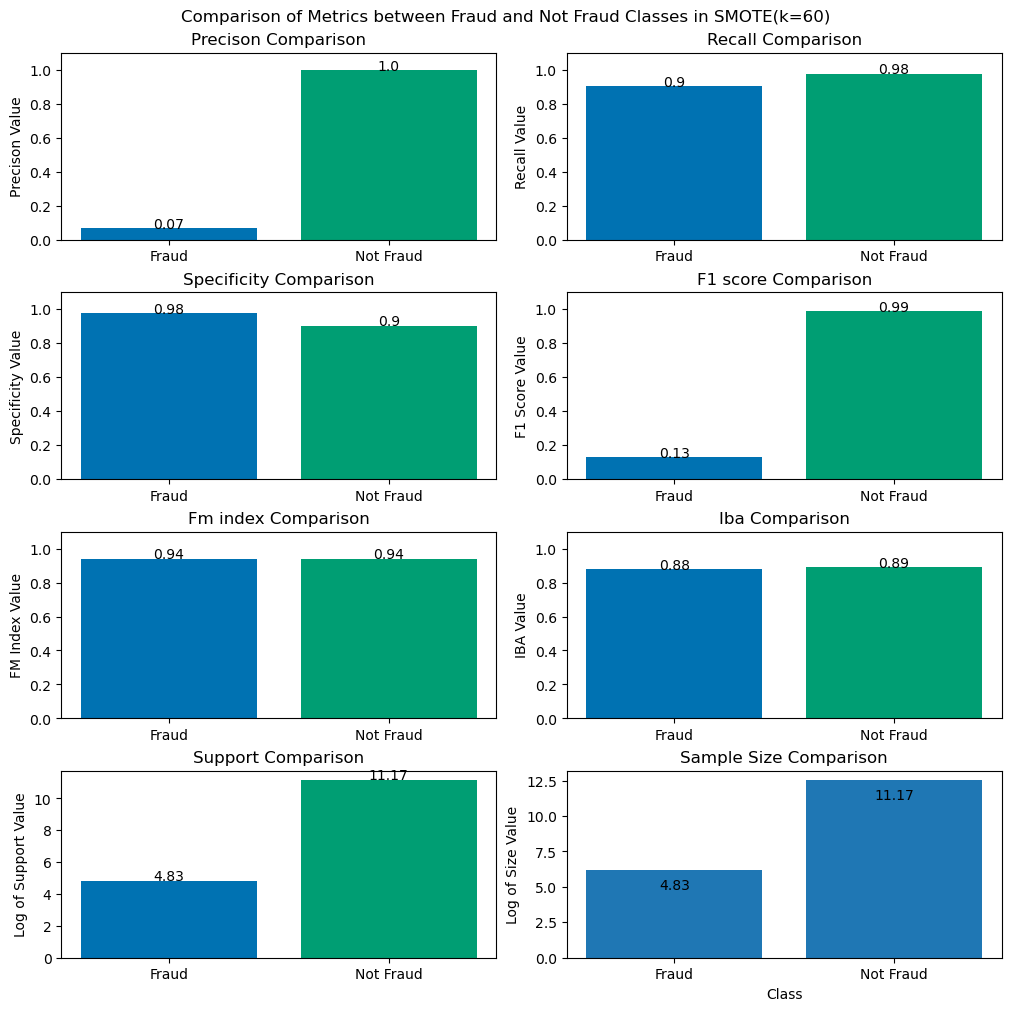

In [32]:
smote = SMOTE(k_neighbors=60)  # TODO: try changing k_neighbors and see what happens
name = "SMOTE(k=60)"
model, r1, r2, df = classify(data, name=name, sampler=smote)
samplers[name] = smote
classifiers[name] = model
sk_reports[name] = r1
im_reports[name] = r2
total_df[name] = df

In [33]:
df

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.070143,0.904,0.130184,0.941462,0.248553,0.978793,0.941462,0.063578,42.892929,0.098067,SMOTE(k=60)


Some Observations:
1. Precision is not good
2. Recall has drastically improved
3. F1 is bad
4. Average Precision is bad

#### Clustering Based Oversampling (CBO) (KMeans-SMOTE)

In this method, we first cluster the data using KMeans into some clusters. We then check for clusters with high density of minority class points. This is to ensure new points are closely related to the class. We then apply SMOTE to only these clusters.<br>
By doing this, we ensure the new data points are not noisy i.e. close to any majority class, ruining the underlying representation

1. **Pro**: Avoids Noise, better generation as per data distribution
2. **Con**: Computationally Expensive and Sensitive to hyperparameters

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


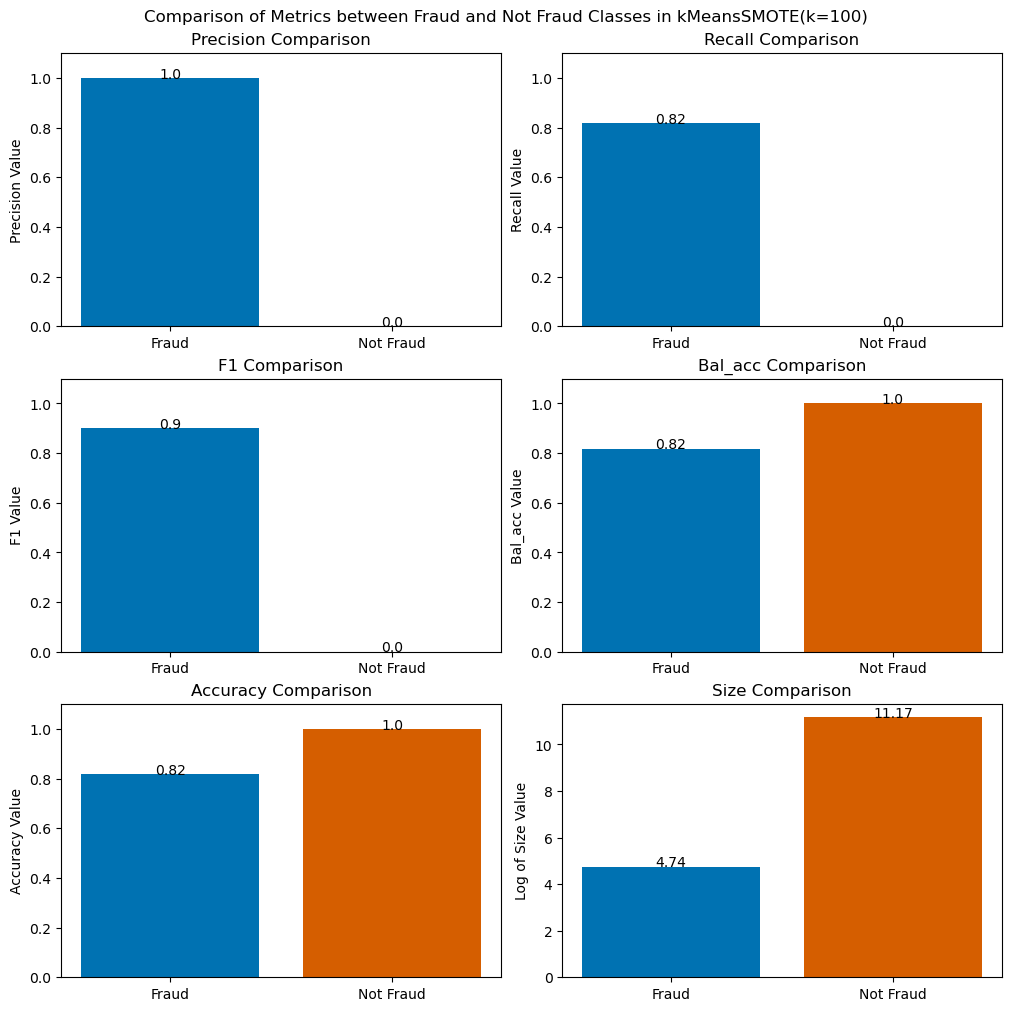

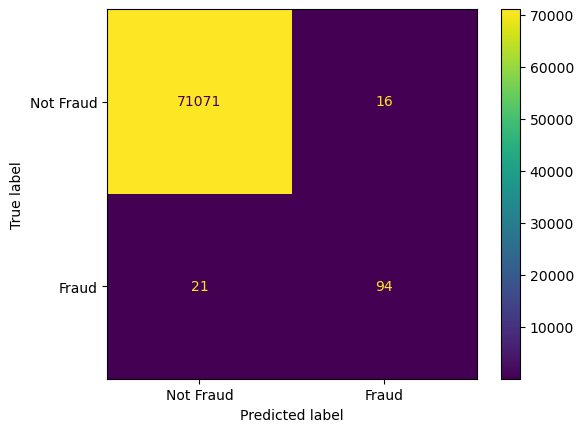

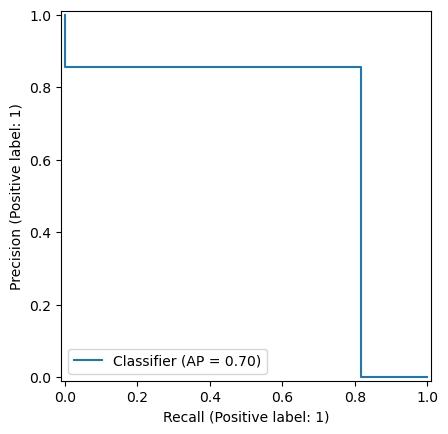

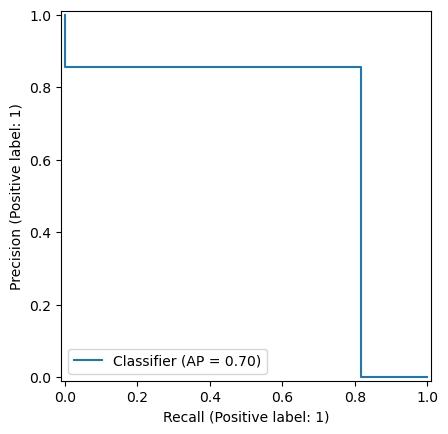

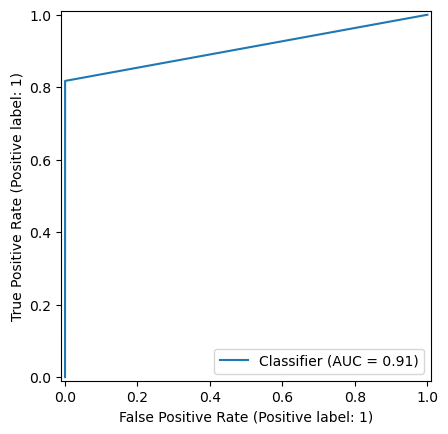

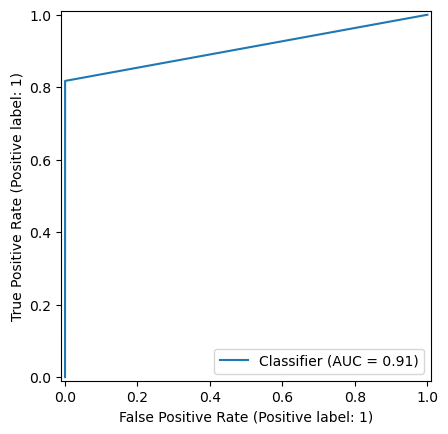

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


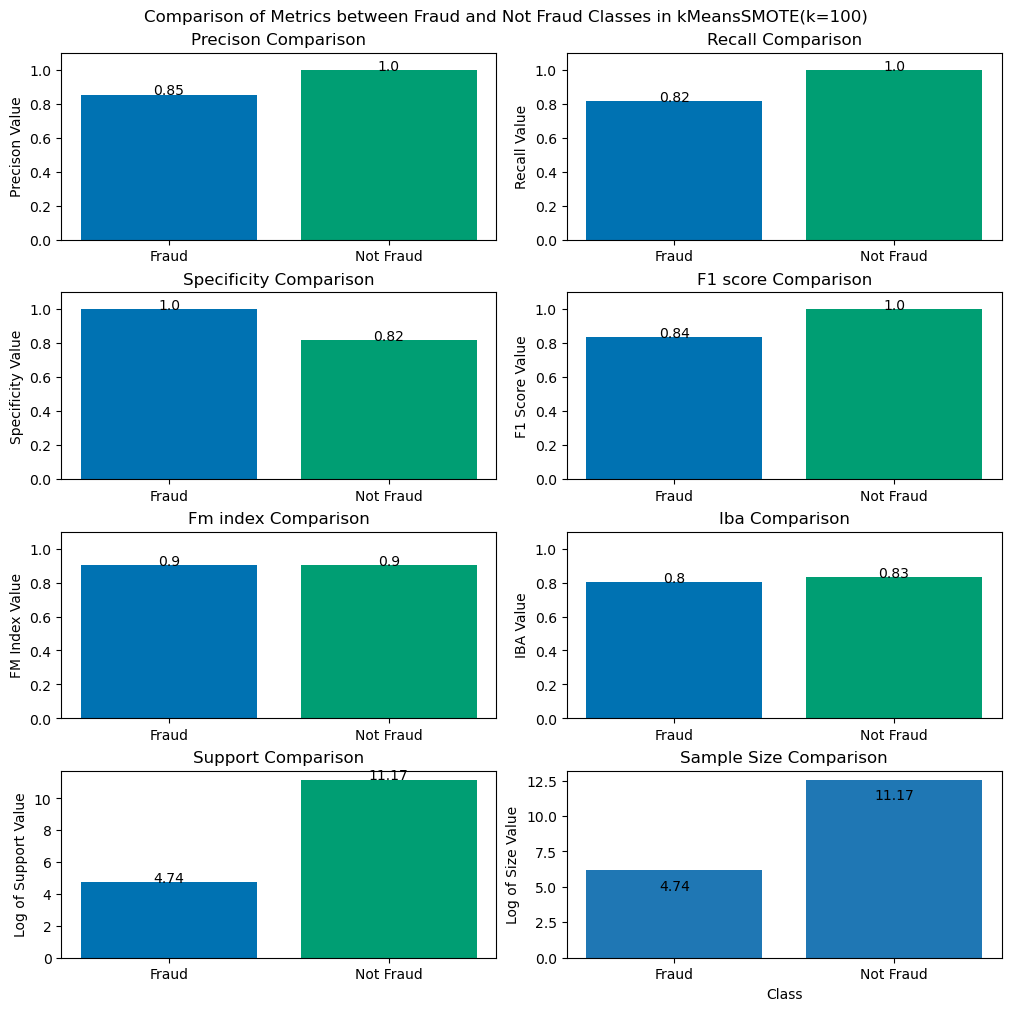

In [34]:
kmeans_smote = KMeansSMOTE(
        kmeans_estimator=MiniBatchKMeans(n_clusters=100, batch_size=2048, n_init='auto'),
        random_state=42
    )
name = "kMeansSMOTE(k=100)"
model, r1, r2, df = classify(data, name=name, sampler=kmeans_smote)
samplers[name] = kmeans_smote
classifiers[name] = model
sk_reports[name] = (r1)
im_reports[name] = (r2)
total_df[name] = (df)

In [35]:
df

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.854545,0.817391,0.835556,0.908583,0.835502,0.99948,0.908583,0.698793,3631.618478,0.18265,kMeansSMOTE(k=100)


Some Observations:
1. Very good F1 score of 0.85 as well as Precision and Recall.
2. The PR Curve is high as well
3. Average Precision is very good
4. MCC has also improved

#### Borderline SMOTE

It focuses more on the data points from the minority class on the class border

1. **Pro**: Efficient, Better for Class boundary
2. **Con**: Sensitive to Noise as it can pick up outliers

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


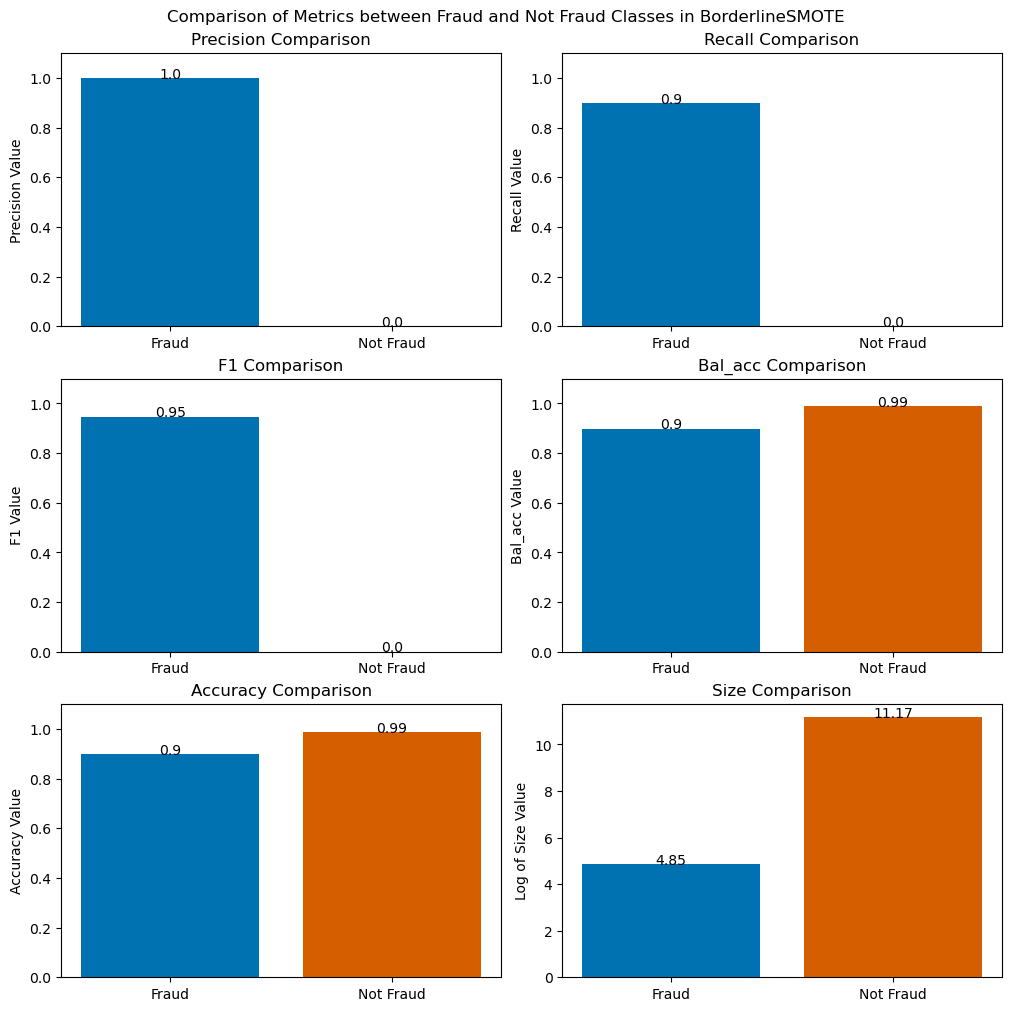

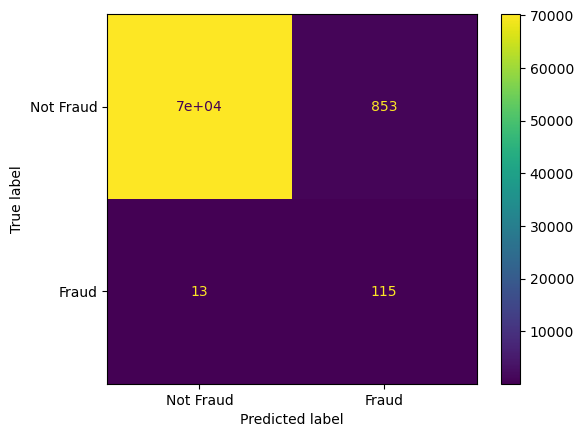

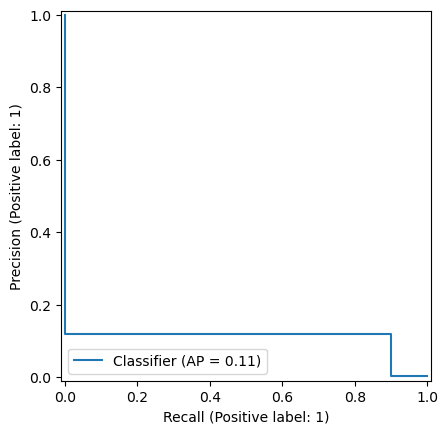

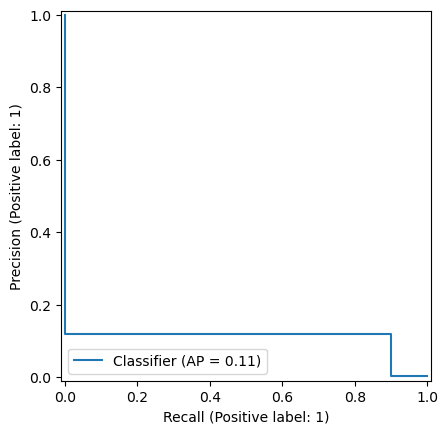

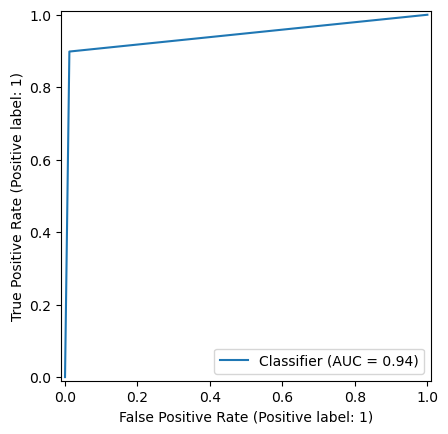

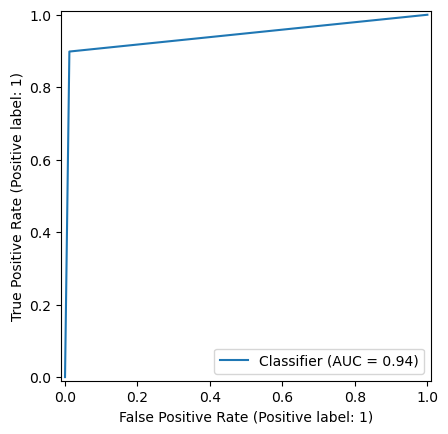

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


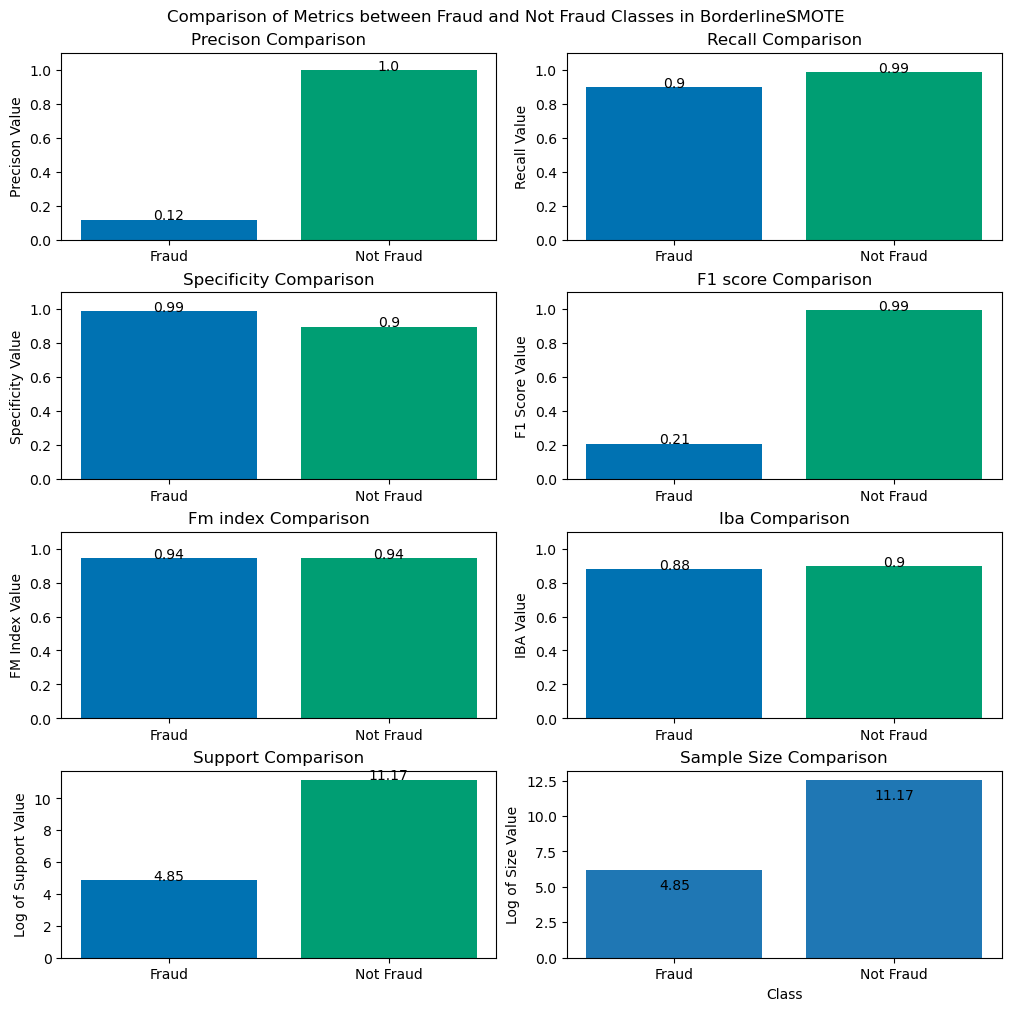

In [36]:
bsmote = BorderlineSMOTE()
name = "BorderlineSMOTE"
model, r1, r2, df = classify(data, name=name, sampler=bsmote)
samplers[name] = (bsmote)
classifiers[name] = (model)
sk_reports[name] = (r1)
im_reports[name] = (r2)
total_df[name] = df

In [37]:
total_df['BorderlineSMOTE']

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.118802,0.898438,0.209854,0.943218,0.324262,0.987837,0.943218,0.106918,74.859961,0.102796,BorderlineSMOTE


Some Observations:
1. Precision, F1 and Average Precision is poor
2. Recall is decent

#### ADASYN (Adaptive Synthetic Sampling)

1. It finds "hard-to-learn" points by assigning a difficulty ratio to each minority class. This ratio calculates the no of majority class neighbors near a minority class point. More the neighbors, harder to learn.
2. It assigns weights to each minority point directly proportional to its difficulty score
3. It then generates points around existing points proportional to their weights

1. **Pro**: Forces Classifier to focus on hard examples, excusing it for soft examples
2. **Con**: It is very sensitive to outliers.

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


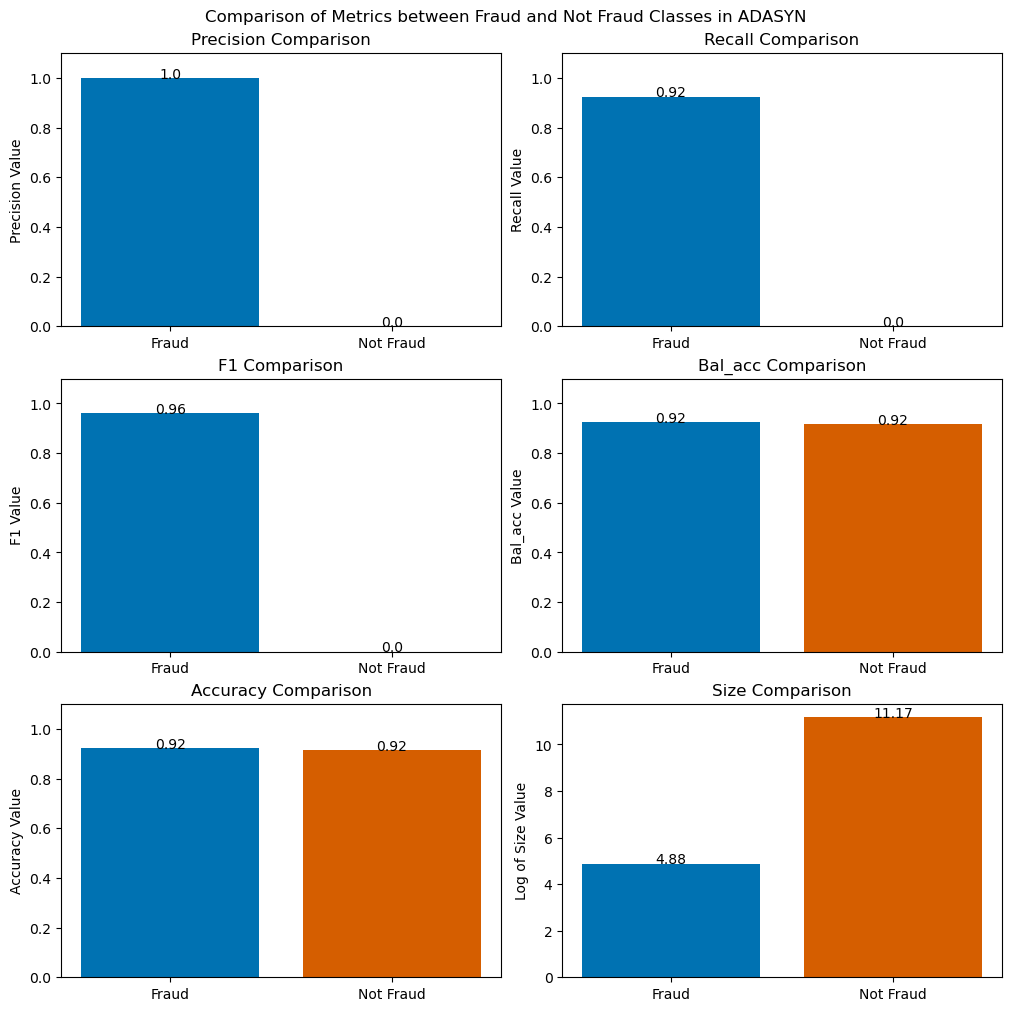

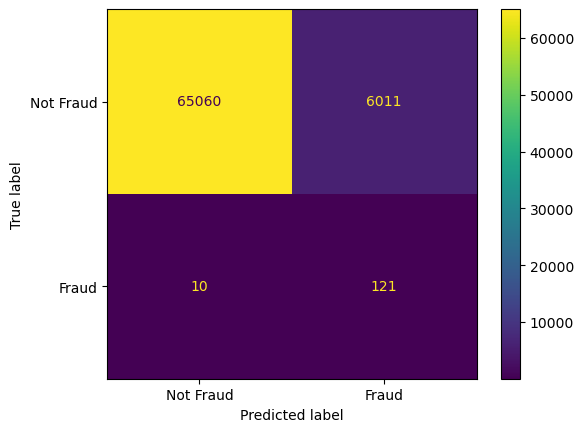

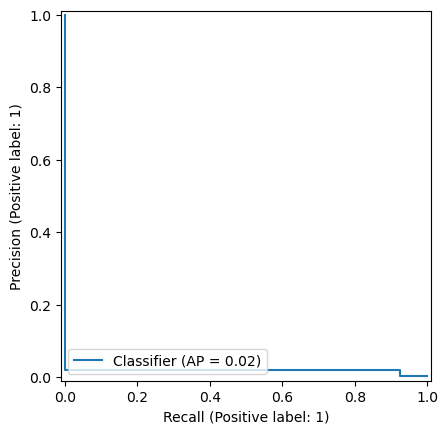

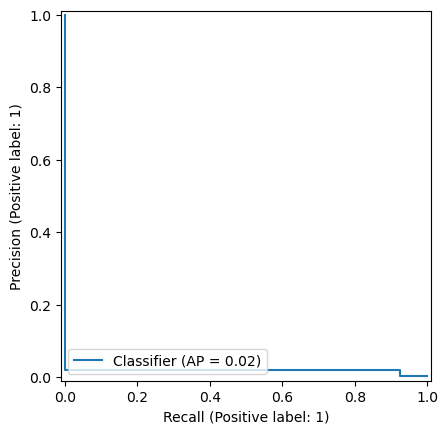

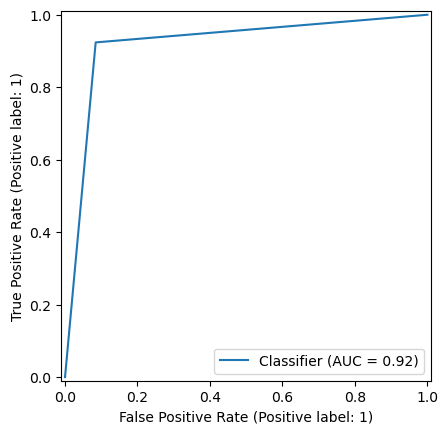

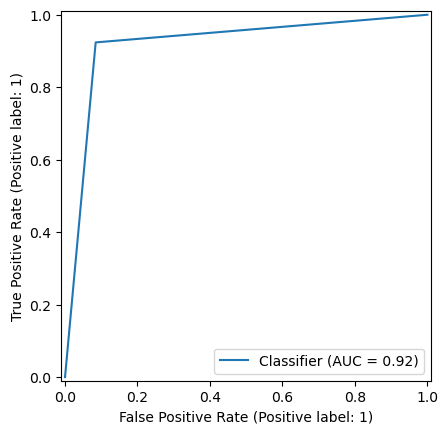

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


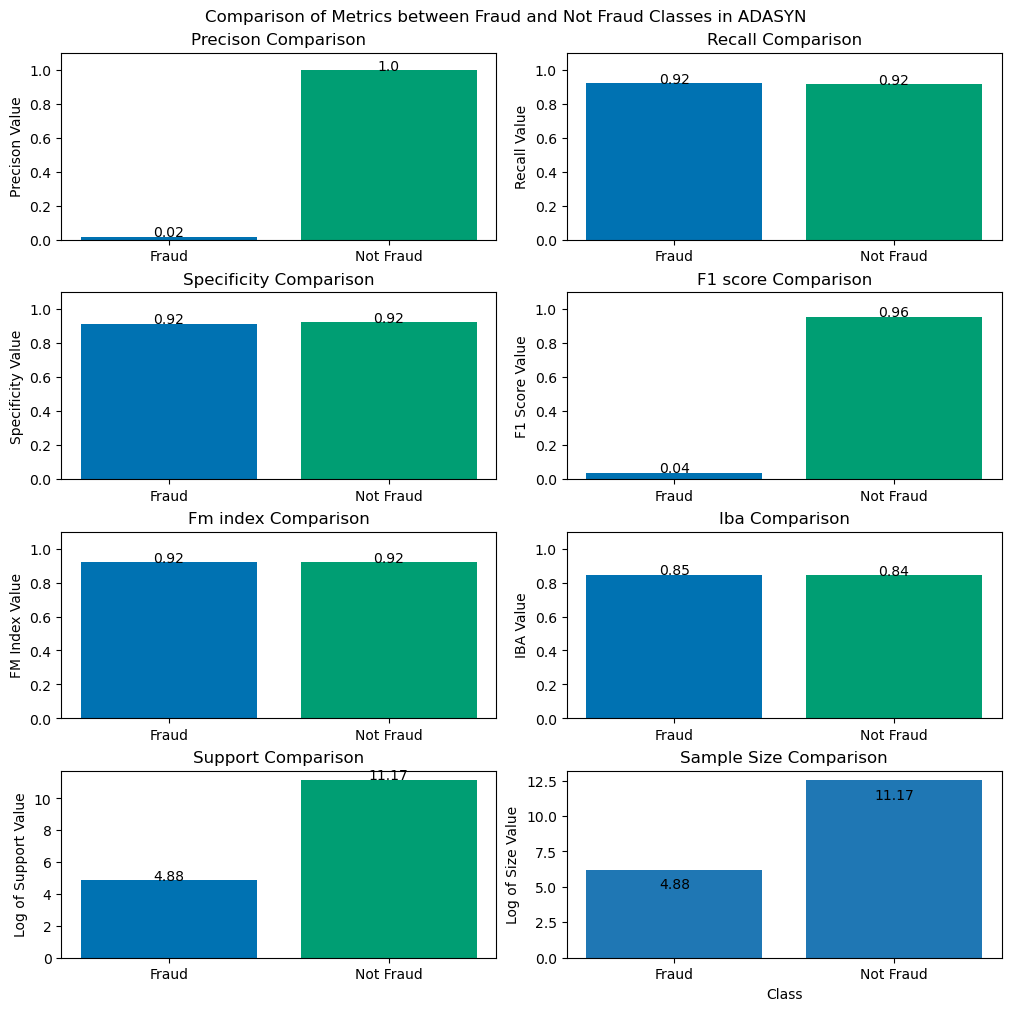

In [38]:
adasyn = ADASYN()
name = "ADASYN"
model, r1, r2, df = classify(data, name=name, sampler=adasyn)
samplers[name] = (adasyn)
classifiers[name] = (model)
sk_reports[name] = (r1)
im_reports[name] = (r2)
total_df[name] = df

In [39]:
total_df['ADASYN']

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.019733,0.923664,0.03864,0.919543,0.128173,0.915438,0.919543,0.018367,10.920934,0.083389,ADASYN


Some observations:
1. Recall is good
2. Precision, F1, Average Precision is very poor

### Undersampling

We can choose to remove certain data points from the majority class. There are different ways of doing the same:

#### Random Under-sampling

Here we remove data points randomly from the dataset. The problem is we can potentially lose vital information about the data

1. **Pro**: Improves class distribution
2. **Con**: Lose vital information about the data

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


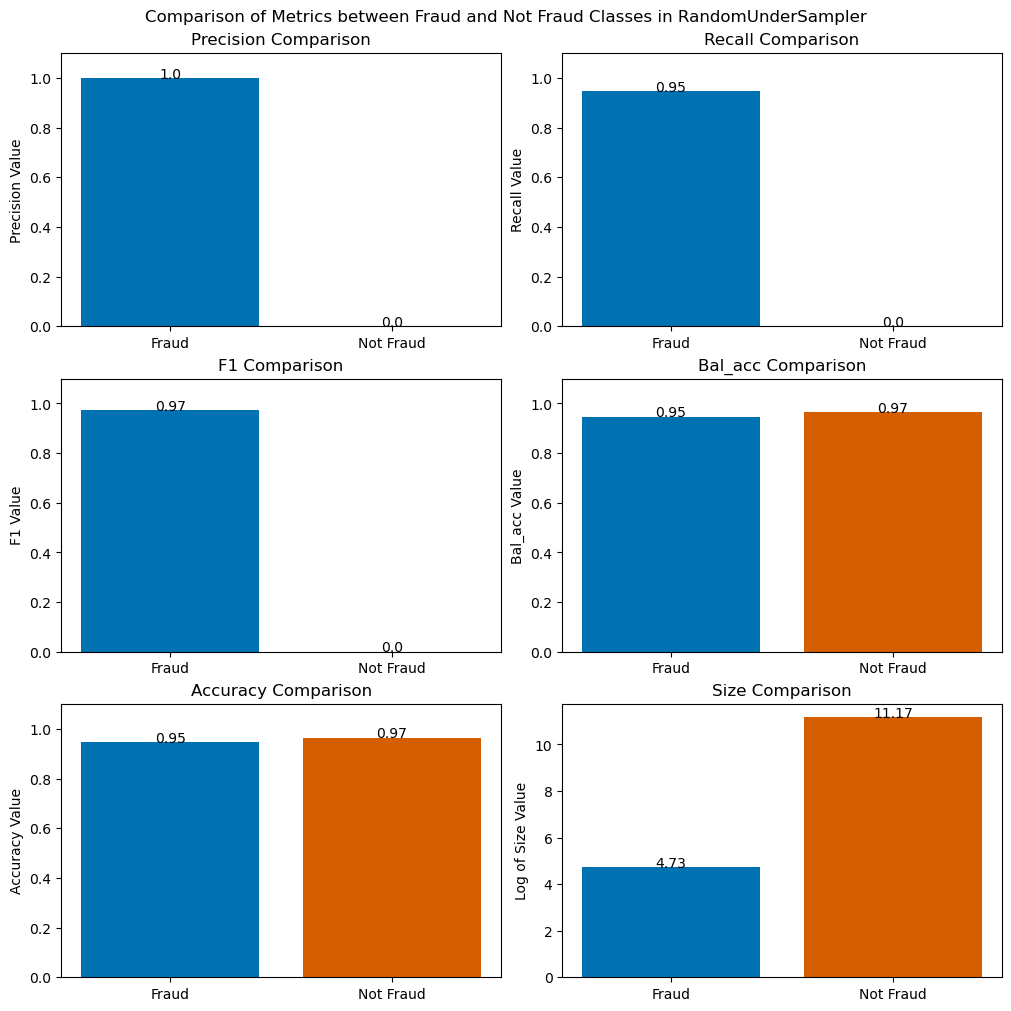

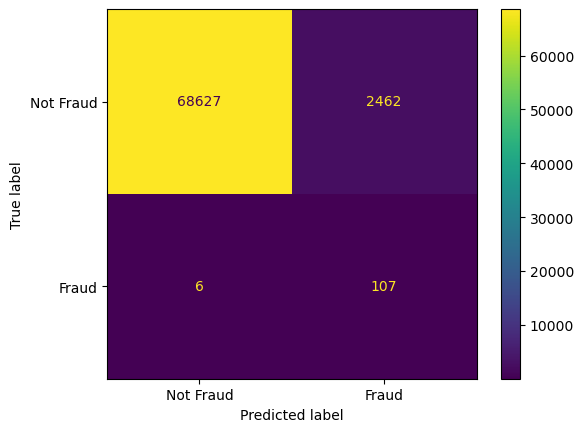

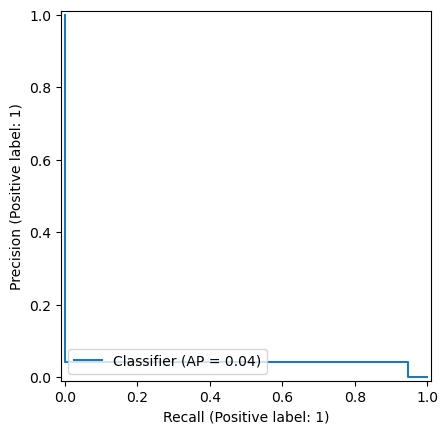

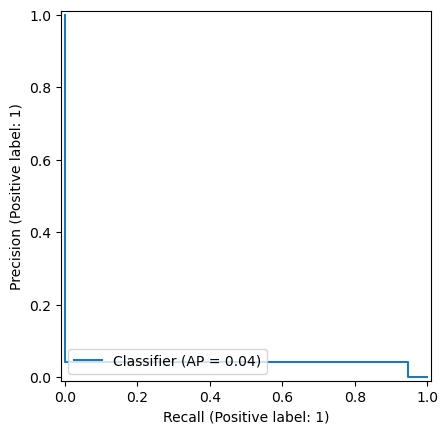

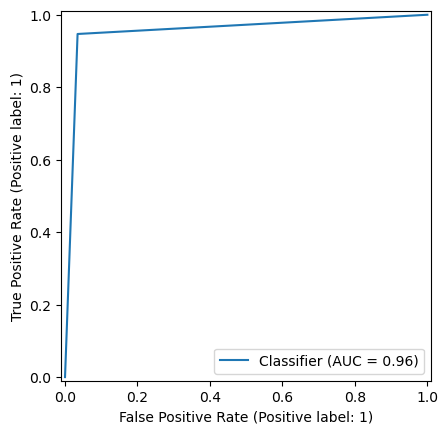

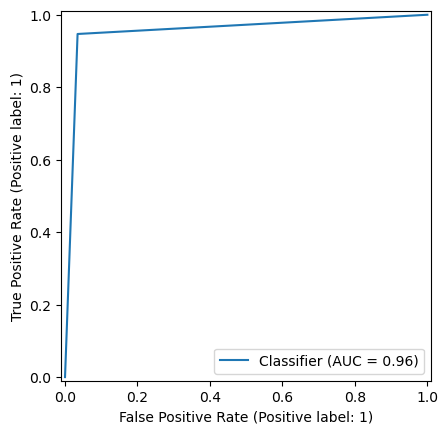

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


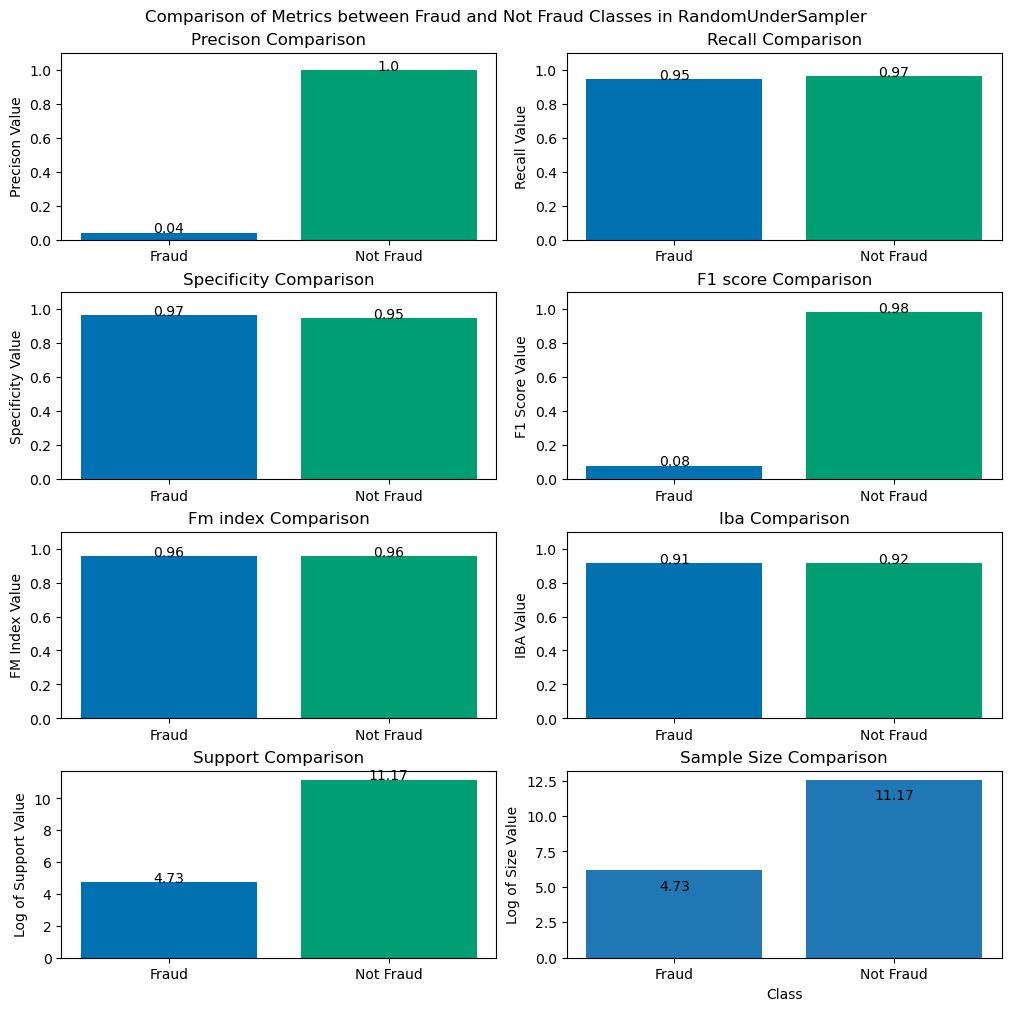

In [40]:
rus = RandomUnderSampler(random_state=42, replacement=True)# fit predictor and target variable
name = "RandomUnderSampler"
model, r1, r2, df = classify(data, name=name, sampler=rus)
samplers[name] = (rus)
classifiers[name] = (model)
sk_reports[name] = (r1)
im_reports[name] = (r2)
total_df[name] = (df)

In [41]:
df

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.04165,0.946903,0.079791,0.956135,0.194722,0.965338,0.956135,0.039523,27.341333,0.055002,RandomUnderSampler


Some observations:
1. Bad Precision, F1, Average Precision
2. Recall is very good

#### Clustering based Undersampling (ClusterCentroids)

We first cluster using KMeans from the majority class and find their centroids. It then discards the rest of the data points and uses just the centroids as the new majority class.<br>
Right from the get-go, we can see why this is bad for our case: our majority class is huge; removing this big chunk of data can lead to loss of valuable information for classification

1. **Pro**: Faster training, better reduction
2. **Con**: Catastrophic loss of information in case of large datasets

/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/pranav-rao/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/tmp/ipykernel_6502/979688706.py:71: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


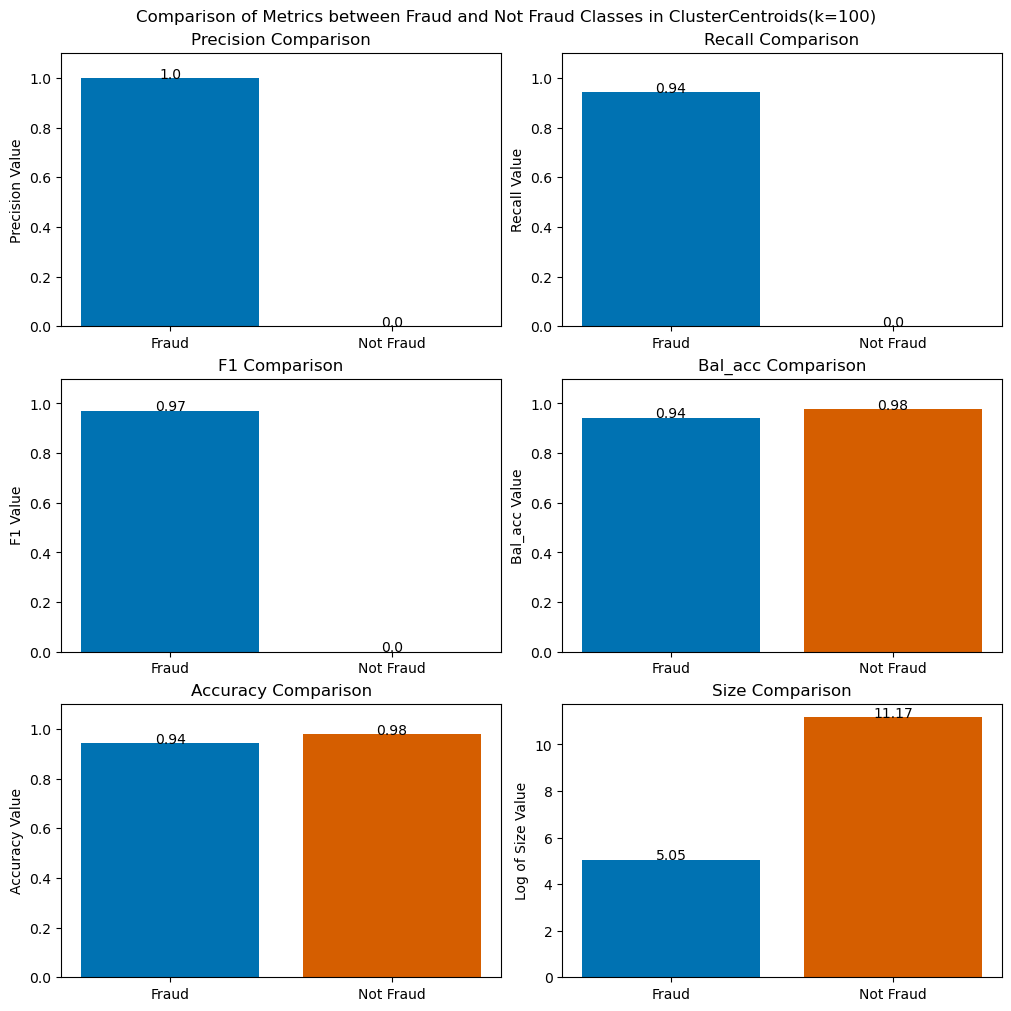

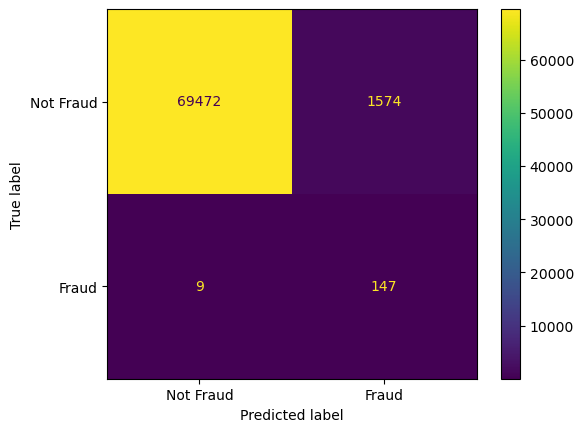

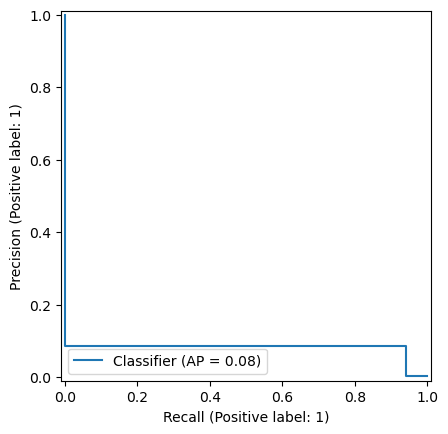

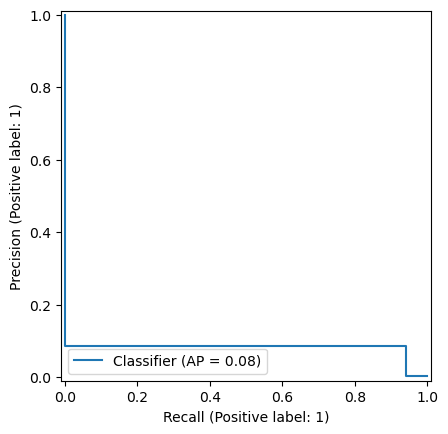

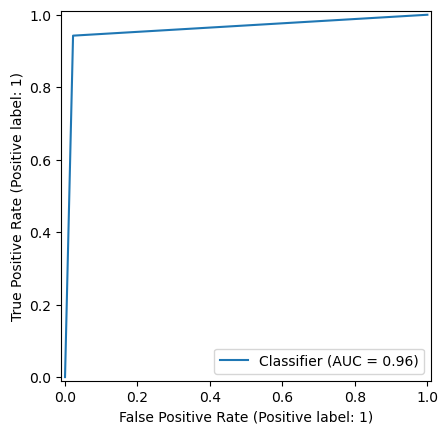

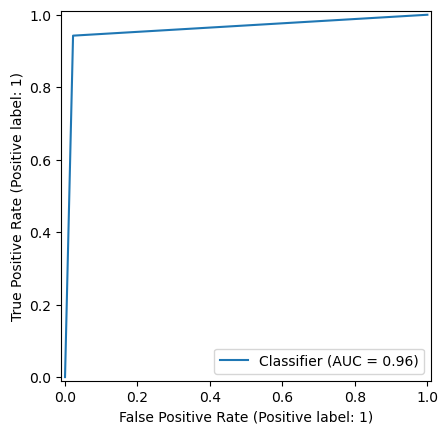

/tmp/ipykernel_6502/1425064076.py:76: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, hspace=0.4)


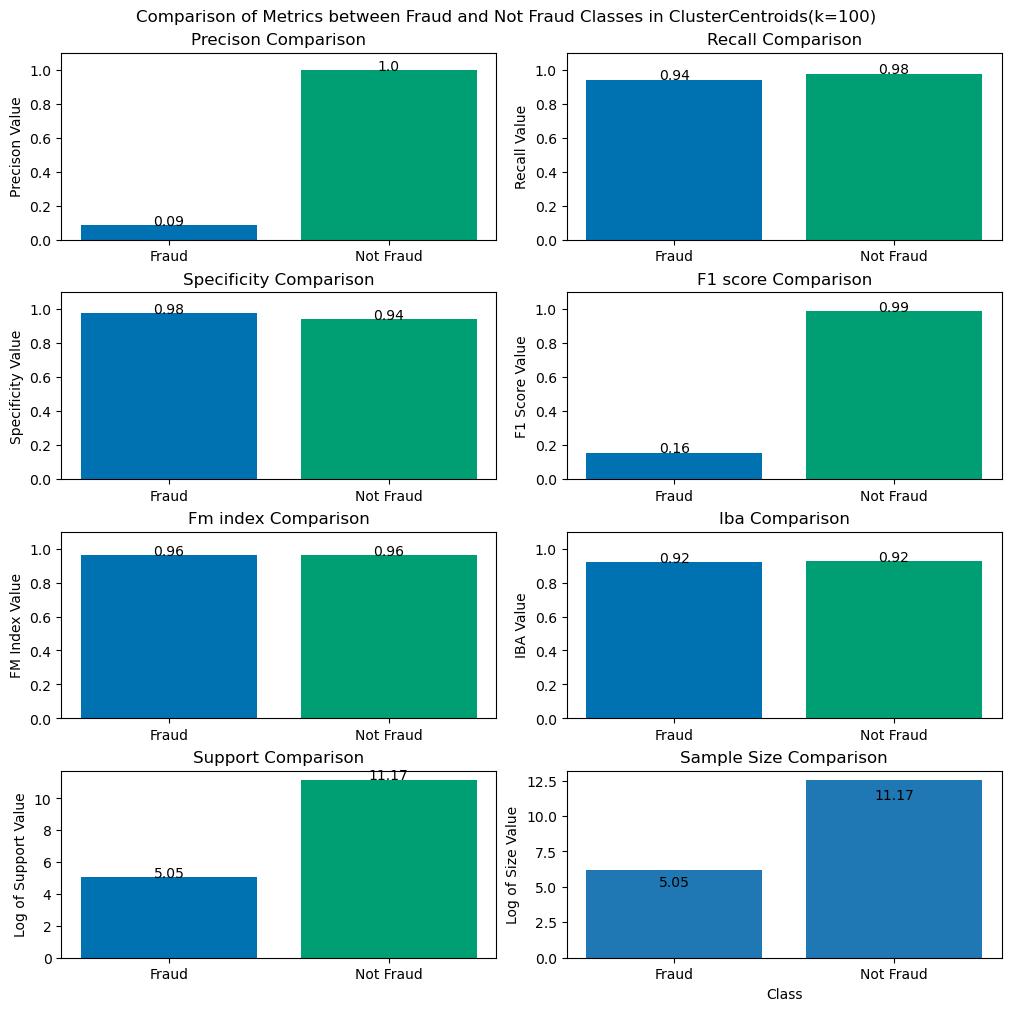

In [42]:
cc = ClusterCentroids(sampling_strategy="majority",
    estimator=MiniBatchKMeans(n_clusters=25)
)
name = "ClusterCentroids(k=100)"
model, r1, r2, df = classify(data, name, cc)
samplers[name] = (cc)
classifiers[name] = (model)
sk_reports[name] = (r1)
im_reports[name] = (r2)
total_df[name] = (df)

In [43]:
df

,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Score,0.085415,0.942308,0.156633,0.960077,0.280136,0.977767,0.960077,0.080614,42.533159,0.058999,ClusterCentroids(k=100)


Some observations:
1. As rightly observed before, the performance is <b>not good</b>. This is as good as a Random sampler or unbalanced classifier

## Explanation of Balanced Metrics

We can use or establish better methods of evaluating a model's performance where we consider more than just the predicted positive points. We want to use those tests which are mostly independent from the data distribution and rather looks into the test's discriminative power.

Let us look at some indices which can be informative to us:<br>
We follow the conventions as:
1. TP - True Positive
2. FP - False Positive
3. TN - True Negative
4. FN - False Negative
5. AP - Actual Positive
6. AN - Actual Negative

#### $Prevalance (P) = \frac{AP}{AP + AN}$
It is defined as the ratio of number of actual positive points to the population size. It depends on the data distribution, and affected by class imbalance. This is very low for our dataset ()

#### $Precision (Positive Predictive Value) (PPV) = \frac{TP}{TP + FP}$
It counts the number of actual positives out of the predicted positives. It depends on Prevalence, and hence affected heavily by class imbalance

#### $Accuracy (A) = \frac{TP + TN}{AN + AP}$
It too heavily depends on the Prevalance.

#### $Recall (R) = \frac{TP}{TP + FN}$
It counts the number of predicted positives out of actual positives. It is instrinstic property of the test, and independent of the data

#### $F1 Score (F1): \frac{2}{F1} = \frac{1}{PPV} + \frac{1}{R}$
It is the Harmonic Mean of Precision and Recall. It too depends on Prevalence, but is a good metric as it encapsulates most of the data

### AUC-ROC
It is the Area under the ROC curve. It too depends on Prevalance.

### AUC-PR
It is the Area under the Precision-Recall Curve. It is independent of Prevalence and hence better than AUC-ROC for imbalanced datasets.

#### $Balanced Accuracy (BA) = \frac{1}{2}(\frac{TP}{TP + FN} + \frac{TN}{FP + TN})$
This is a balanced version of Accuracy taking in account of both Positive and Negative Accuracies, and hence works well for imbalanced datasets

#### Matthew's Correlation Coefficent (MCC)
This is regarded as the best metric for imbalanced datasets as it takes into account various facets of the data

Use AUCPRC or MCC or balanced accuracy instead of F1, Precision and Recall

## PART C : Results

We examine and compare different methods here

In [44]:
del sk_reports['RandomOverSampler(shrinkage = 0.3)']

In [46]:
len(sk_reports)

9

precision
recall
f1
bal_acc
mcc
accuracy
roc_auc
avg_p


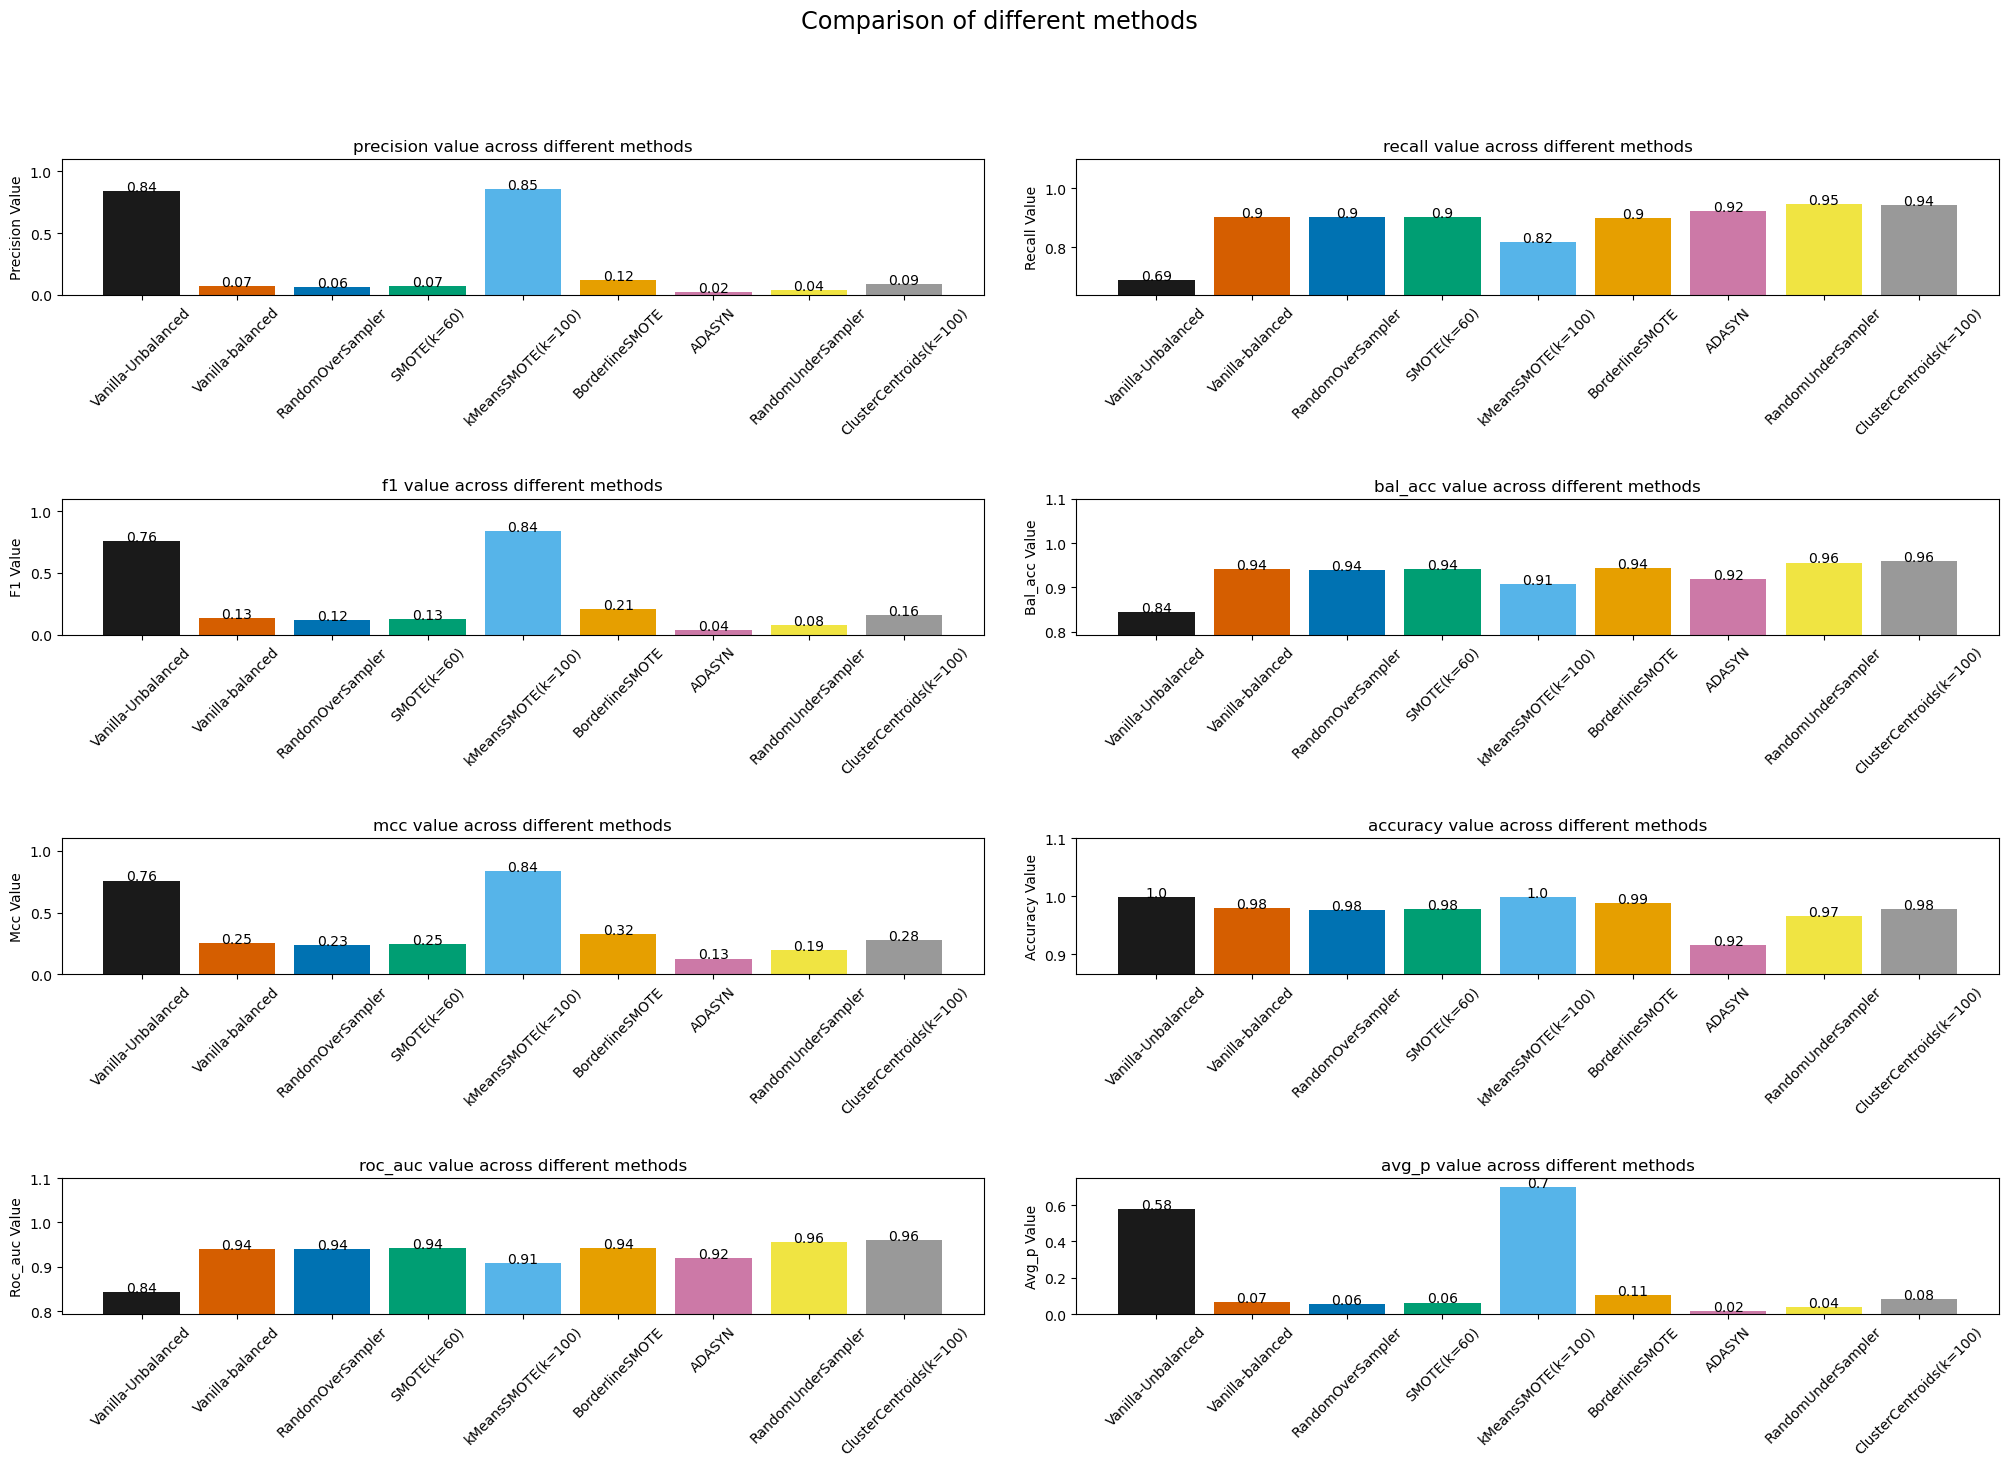

In [50]:
# Plot of Report generated using sklearn
metrics = list(sk_reports['ADASYN'].keys())
for i in ["pr_curve", "confusion_matrix", "roc_curve", "Fraud", "Not Fraud", "likelihood_ratios"]:
    metrics.remove(i)

fig, axs = plt.subplots(4, 2, figsize = (25, 15))
i, j = 0, 0
color_palette = [
    '#1A1A1A',  # Onyx
    '#D55E00',  # Vermillion
    '#0072B2',  # Cerulean Blue
    '#009E73',  # Shamrock Green
    '#56B4E9',  # Sky Blue
    '#E69F00',  # Amber
    '#CC79A7',  # Pale Violet
    '#F0E442',  # Canary Yellow
    '#999999'   # Gray
]
for metric in metrics:
    print(metric)
    ax = axs[i, j]
    vals = [sk_reports[report][metric] for report in sk_reports]
    ax.bar(x=list(sk_reports.keys()), height=vals, color=color_palette)
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_ylabel(f"{metric.capitalize()} Value")
    if not all(isinstance(i, tuple) for i in vals):
        m = 1.1 if max(vals) > 0.7 else max(vals) + 0.05
        n = 0 if min(vals) < 0.3 else min(vals) - 0.05
        ax.set_ylim(n, m)
    ax.set_title(f"{metric} value across different methods")
    for q in range(len(vals)):
        ax.text(q, vals[q], np.round(vals[q], 2), ha='center')  # Aligning text at center
    j += 1
    if j == 2:
        i += 1
        j = 0

fig.suptitle("Comparison of different methods", fontsize='xx-large')
plt.savefig("images/total_sk_report.png")
# fig.align_xlabels(axs)
plt.subplots_adjust(wspace=0.1, hspace=1.5)
plt.show()

As we can see, **KMeans + SMOTE** stands out in majority of these plots<br>
Even Vanilla Unbalanced performs decently

In [48]:
del im_reports['RandomOverSampler(shrinkage = 0.3)']

In [49]:
metrics = list(im_reports['ADASYN'].keys())
for i in ["Fraud", "Not Fraud", "Total Support"]:
    metrics.remove(i)
len(metrics)

7

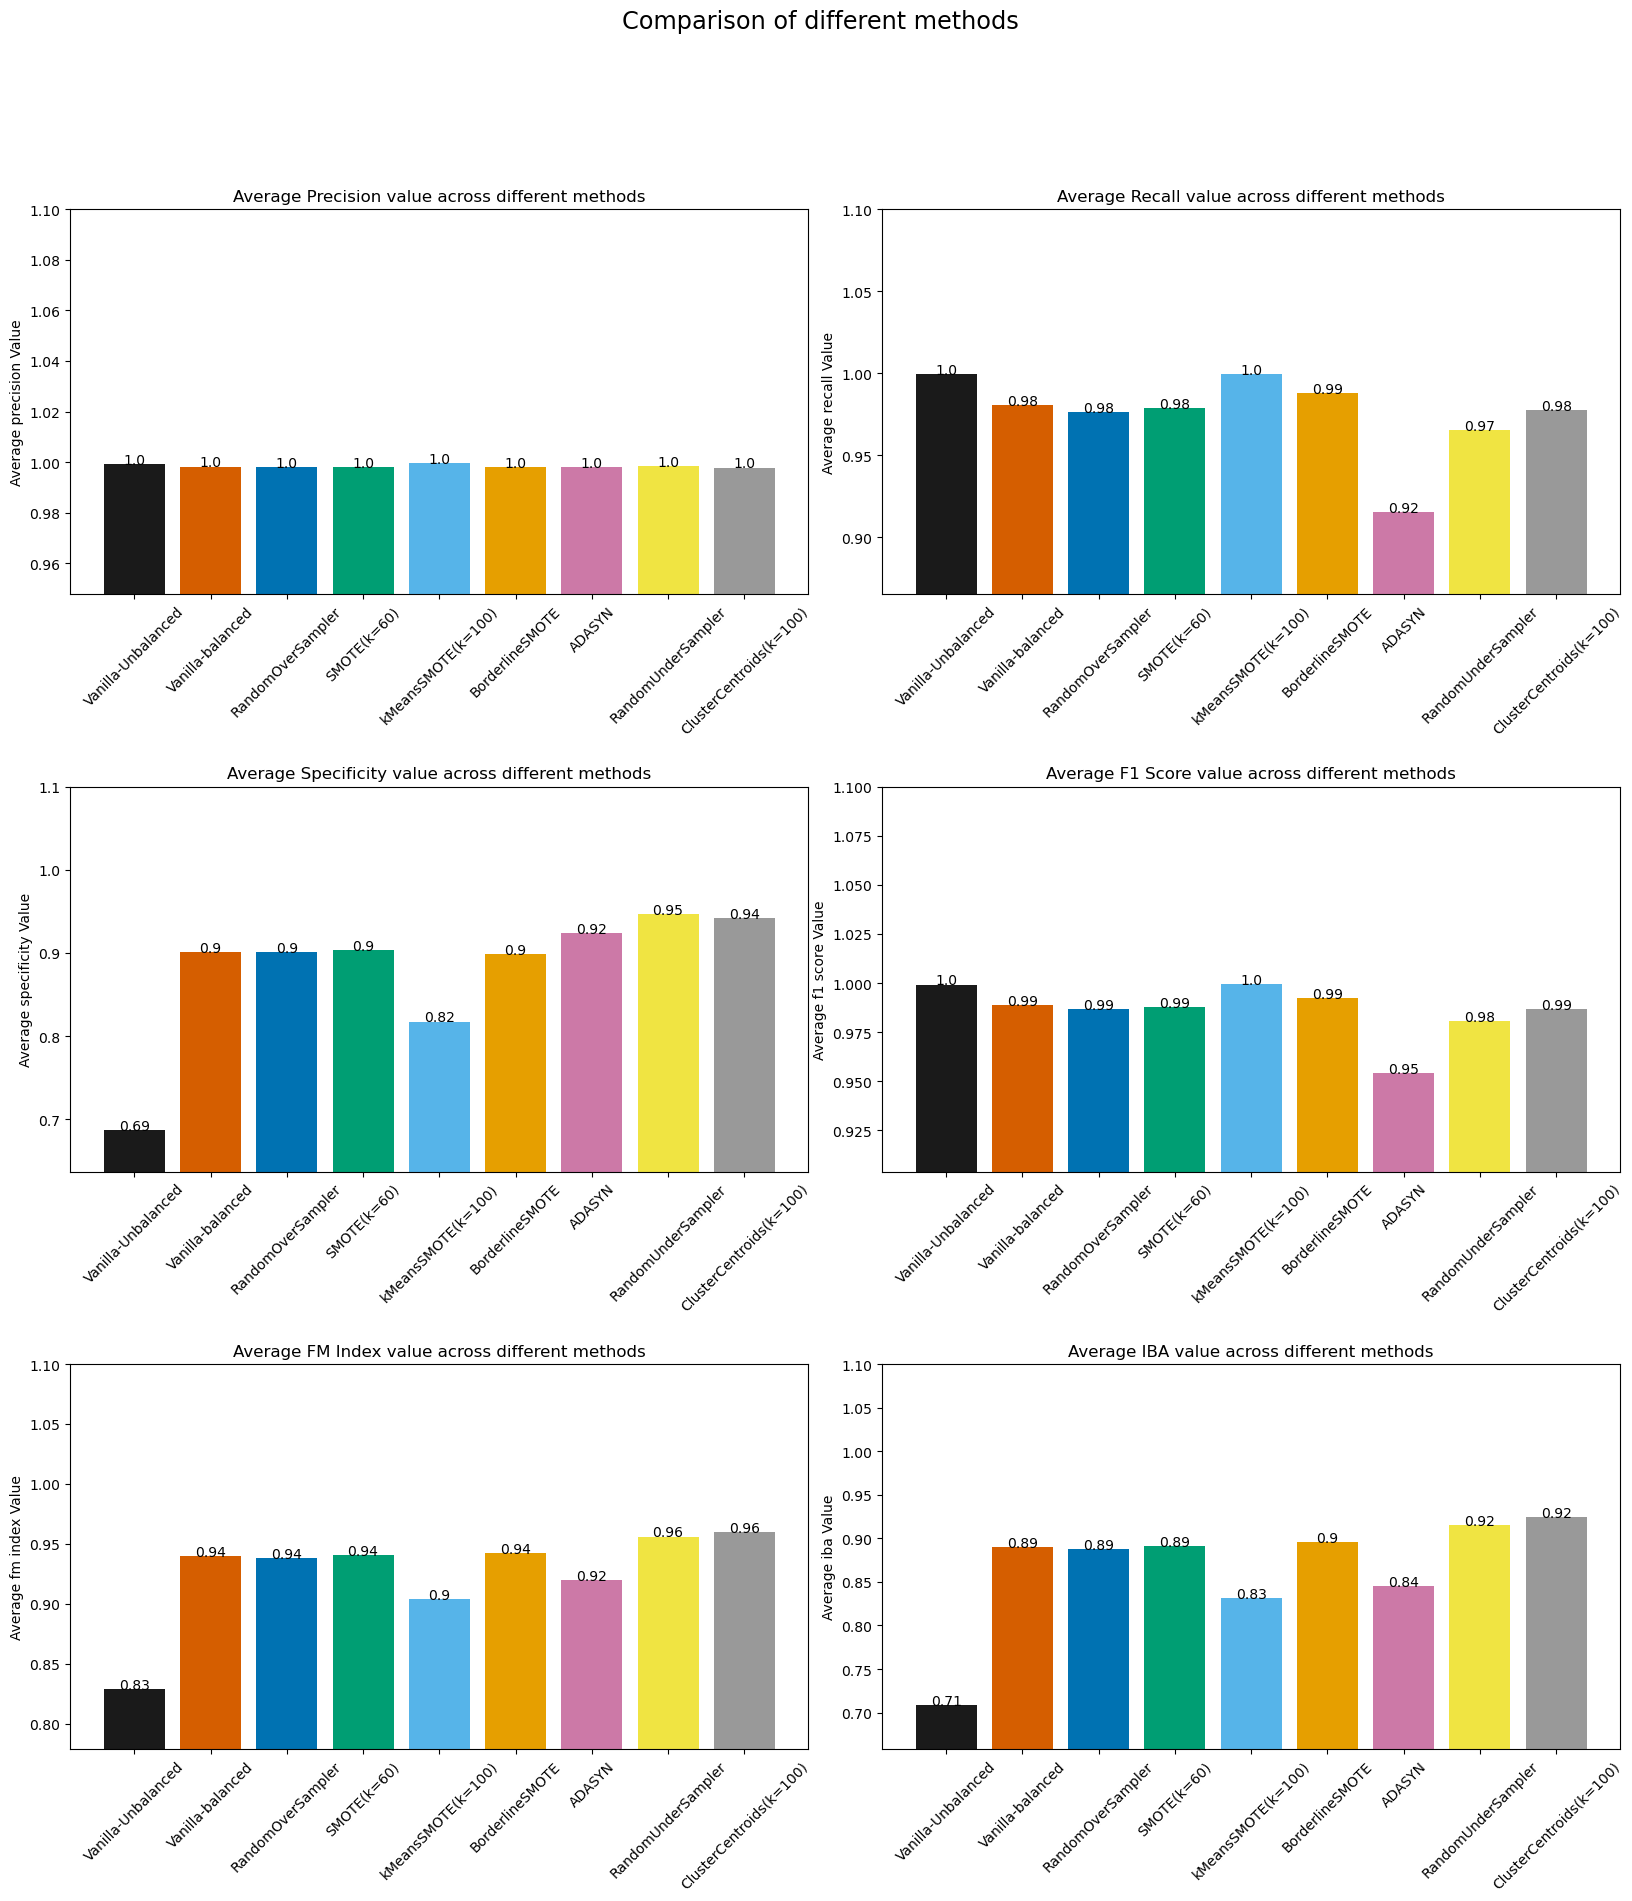

In [59]:
# Plot of report using imblearn
metrics = list(im_reports['ADASYN'].keys())
for i in ["Fraud", "Not Fraud", "Total Support", "Average Index Balanced Accuracy"]:
    metrics.remove(i)

fig, axs = plt.subplots(3, 2, figsize = (20, 20))
i, j = 0, 0
color_palette = [
    '#1A1A1A',  # Onyx
    '#D55E00',  # Vermillion
    '#0072B2',  # Cerulean Blue
    '#009E73',  # Shamrock Green
    '#56B4E9',  # Sky Blue
    '#E69F00',  # Amber
    '#CC79A7',  # Pale Violet
    '#F0E442',  # Canary Yellow
    '#999999'   # Gray
]
for metric in metrics:
    ax = axs[i, j]
    vals = [im_reports[report][metric] for report in im_reports]
    ax.bar(x=list(im_reports.keys()), height=vals, color=color_palette)
    ax.tick_params(axis='x', labelrotation=45)
    ax.set_ylabel(f"{metric.capitalize()} Value")
    if not all(isinstance(i, tuple) for i in vals):
        m = 1.1 if max(vals) > 0.7 else max(vals) + 0.05
        n = 0 if min(vals) < 0.3 else min(vals) - 0.05
        ax.set_ylim(n, m)
    ax.set_title(f"{metric} value across different methods")
    for q in range(len(vals)):
        ax.text(q, vals[q], np.round(vals[q], 2), ha='center')  # Aligning text at center

    j += 1
    if j == 2:
        i += 1
        j = 0

fig.suptitle("Comparison of different methods", fontsize='xx-large')
plt.savefig("images/total_im_report.png")
# fig.align_xlabels(axs)
plt.subplots_adjust(wspace=0.1, hspace=0.5)
plt.show()

Here we can see that most of the models give a decent result according to these metrics

In [ ]:
# show_decision_functions(data)

In [47]:
comp_df = pd.concat(total_df, axis=0)

In [48]:
comp_df

,,precision,recall,f1,bal_acc,mcc,accuracy,roc_auc,avg_p,positive_likelihood_ratio,negative_likelihood_ratio,name
Vanilla-Unbalanced,Score,0.853659,0.598291,0.703518,0.799061,0.71428,0.999171,0.799061,0.511396,3544.123932,0.401777,Vanilla-Unbalanced
Vanilla-balanced,Score,0.066298,0.892562,0.123429,0.935582,0.239987,0.978456,0.935582,0.059358,41.712162,0.109787,Vanilla-balanced
RandomOverSampler,Score,0.058275,0.884956,0.109349,0.931112,0.223796,0.977121,0.931112,0.051753,38.929839,0.11772,RandomOverSampler
RandomOverSampler(shrinkage = 0.3),Score,0.063636,0.867257,0.118572,0.923486,0.231767,0.979537,0.923486,0.0554,42.75479,0.135492,RandomOverSampler(shrinkage = 0.3)
SMOTE(k=60),Score,0.061159,0.926829,0.114746,0.951104,0.234651,0.975296,0.951104,0.05681,37.644627,0.075018,SMOTE(k=60)
kMeansSMOTE(k=100),Score,0.860656,0.813953,0.836653,0.906857,0.836692,0.999424,0.906857,0.700871,3402.948016,0.186091,kMeansSMOTE(k=100)
BorderlineSMOTE,Score,0.120267,0.830769,0.210117,0.909827,0.313562,0.988596,0.909827,0.100223,74.739786,0.171133,BorderlineSMOTE
ADASYN,Score,0.019424,0.926829,0.038051,0.922932,0.127725,0.919047,0.922932,0.018129,11.447106,0.079617,ADASYN
RandomUnderSampler,Score,0.042237,0.948718,0.080874,0.956655,0.196204,0.964566,0.956655,0.040156,26.793649,0.053165,RandomUnderSampler
ClusterCentroids(k=100),Score,0.06038,0.905172,0.113208,0.941093,0.230491,0.976897,0.941093,0.054808,39.378878,0.097059,ClusterCentroids(k=100)


Best in:
1. Precision : KMeans + SMOTE
2. Recall : RandomUnderSampler
3. F1 : KMeans + SMOTE
4. Bal-ACC : RandomUnderSampler
5. MCC : KMeans + SMOTE
6. Acc : KMeans + SMOTE
7. ROC-AUC: RandomUnderSampler
8. Avg-P:KMeans + SMOTE

Except for Vanilla Unbalanced and KMeans + SMOTE, all of the models decided to prioritise Recall over Precision<br>
Vanilla Unbalanced prioritised Precision over Recall<br>
KMeans + SMOTE was able to give both equal weight

In [49]:
comp_df.to_csv('comparison_metrics.csv', index=False)

## PART C : Conclusion

After running various experiments for the given task on different resampling method, we can safely conclude that <b>KMeans + SMOTE</b> is the best classification pipeline, achieving <?><br>
This is because this method oversamples the minority class in the clusters with their high density, ensuring that the features are preserved. SMOTE assumes that the features of the data can be combined linearly (by taking the synthetic point along a line) which is simple but fair assumption in most cases.

If we were to cluster the data according to the first two principal components, we see that the data is not linearly seperable. This means that for a minority point, its neighbors can be majority points. SMOTE picks the neighbors indiscriminately and can pick points which are in between a majority and a minority point (also known as a tomek link). This leads to poor generalization for the minority class. Clustering ensures we pick from the points which are surronded by similar points.

Hence, the company should use <b>KMeans + SMOTE</b> method if they are fine with computationally heavy task, else a **normal** classification is sufficient